# 01 - Replikasi MosquitoSong+ (Supratak et al., PLOS ONE 2024)

Notebook ini mereplikasi **Eksperimen 1** paper *MosquitoSong+: A noise-robust deep learning model for mosquito classification from wingbeat sounds*: klasifikasi spesies dan sex nyamuk (8 kelas) dari raw waveform 300 ms, dengan noise lingkungan disimulasikan pada test.

| Metode | Inisialisasi | Training dan augmentasi | Peran |
|---|---|---|---|
| MosquitoSong | Bobot acak | Adam 1e-4, 1000 epoch; time shift, amplitudo, Gaussian noise; **tanpa** noise lingkungan | Model sebelumnya (baris 1-2 Tabel 3 paper) |
| MosquitoSong+ | Bobot acak | Adam 1e-4, 1000 epoch; augmentasi MosquitoSong **+ noise N-OUTDOOR (p = 0,9) + volume G ~ U(1, 2)** | Model yang diusulkan paper (baseline) |
| Checkpoint rilis penulis | Bobot dari repo | Tanpa training, hanya evaluasi | Acuan replikasi (arsitektur MosquitoSong) |

Repo penulis (`akaraspt/mosquitosongp`) hanya merilis notebook **inferensi** dan checkpoint, tanpa kode training. Karena itu fungsi segmentasi, split fold, dan pembuatan validation/test di bawah adalah **port 1:1 dari `prediction.ipynb`**, sedangkan arsitektur, augmentasi, dan training direkonstruksi dari teks paper.

**Cara menjalankan di Kaggle**

1. *Add Input*: dataset rekaman (`mosquito_recordings`, `environmental_noise_recordings`), output versi notebook ini sebelumnya (berisi `runs/`), dan bila ada, folder `models/` dari repo penulis.
2. *Accelerator*: **GPU T4 ×2**, lalu **Save Version → Save & Run All**.
3. Fold yang sudah lengkap dilewati, fold yang terjeda dilanjutkan dari checkpoint. Ulangi langkah 1-2 sampai tabel status menunjukkan 10/10.

Sel bertanda `# [lib]` berisi fungsi inti. Sel-sel ini digabung menjadi `mosq_lib.py` sehingga setiap fold berjalan sebagai proses sendiri (dua fold paralel bila ada dua GPU).

## 1. Setup dan Konfigurasi

Nilai default mengikuti paper (1000 epoch, 10 fold, fp32). Analisis data (bagian 5) hanya memakai CPU dan selesai dalam beberapa menit.

In [1]:
# [lib] impor-dan-konstanta
import os, re, sys, math, json, time, glob, random, shutil, platform
from types import SimpleNamespace

import numpy as np
import pandas as pd
import soundfile as sf
import tensorflow as tf
import keras
from keras import layers as L
from keras import ops

SR = 8000            # sampling rate (Hz)
TARGET = 2400        # 1 epoch = 300 ms
GAINS = (1, 1.5, 2)  # faktor volume wingbeat G pada validation/test
CLASSES = ['Ae.Aegypti_F', 'Ae.Aegypti_M', 'Ae.Albopictus_F', 'Ae.Albopictus_M',
           'An.Dirus_F', 'An.Dirus_M', 'Cx.Quin_F', 'Cx.Quin_M']   # urutan sama dengan LabelEncoder
SHORT = ['Ae.aeg F', 'Ae.aeg M', 'Ae.alb F', 'Ae.alb M', 'An.dir F', 'An.dir M', 'Cx.quin F', 'Cx.quin M']

In [2]:
WORK = '/kaggle/working' if os.path.isdir('/kaggle/working') else os.getcwd()
INPUT = os.environ.get('MOSQ_INPUT', '/kaggle/input')   # lokasi dataset & output versi sebelumnya
os.chdir(WORK)
SMOKE = False
MAX_TRAIN = 0                                          # 0 = semua data train (uji lokal memakai subsampel)

PRECISION = 'fp32'      # 'fp32' setara paper | 'fp16' lebih cepat di T4
FOLD_ROUNDS = list(range(10))
TIME_BUDGET_H = 11.3    # sesi Kaggle maks. 12 jam; setelah batas ini fold berjalan dijeda + checkpoint
SEED = 42
EPOCHS_PAPER = 1000

EXPERIMENTS = {
    'mosquitosong_plus': dict(model='mosquitosong_plus', recipe='paper', epochs=EPOCHS_PAPER, lr=1e-4),
    'mosquitosong':      dict(model='mosquitosong',      recipe='paper', epochs=EPOCHS_PAPER, lr=1e-4),
}
RUN = list(EXPERIMENTS)


random.seed(SEED); np.random.seed(SEED); keras.utils.set_random_seed(SEED)
import sklearn
print({'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
       'tensorflow': tf.__version__, 'keras': keras.__version__, 'scikit_learn': sklearn.__version__, 'seed': SEED})
print('GPU devices:', tf.config.list_physical_devices('GPU'))
print('Work dir:', WORK, '| fold:', FOLD_ROUNDS)

{'python': '3.13.16', 'numpy': '2.1.3', 'pandas': '2.3.3', 'tensorflow': '2.21.0', 'keras': '3.13.2', 'scikit_learn': '1.6.1', 'seed': 42}
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Work dir: /kaggle/working | fold: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


In [3]:
# Dependensi lain (TF/Keras, soundfile, sklearn, scipy, seaborn) sudah ada di image Kaggle.
try:
    import imblearn; print('imbalanced-learn', imblearn.__version__)
except ImportError:
    import subprocess
    r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'imbalanced-learn'], capture_output=True)
    print('imbalanced-learn:', 'terpasang' if r.returncode == 0 else 'gagal, memakai fallback numpy setara')

imbalanced-learn 0.14.2


## 2. Memuat Data

Dataset W-INDOOR berisi 1.324 rekaman wingbeat (4 spesies × 2 sex, mikrofon kondenser dan mikrofon low-cost `LowMic`), sudah di-downsample ke 8 kHz/16-bit. N-OUTDOOR berisi 12 rekaman noise stereo (kendaraan, hewan, aktivitas manusia, kipas perangkap). Notebook mencari kedua folder di Input secara otomatis, lalu menyalin hasil fold dari output versi sebelumnya.

In [4]:
def find_dir(name):
    """Cari folder berisi wav di INPUT (atau MOSQ_DATA untuk uji lokal); zip mentah juga didukung."""
    roots = [r for r in (os.environ.get('MOSQ_DATA', ''), INPUT, WORK) if r and os.path.isdir(r)]
    for r in roots:
        for d in glob.glob(os.path.join(r, '**', name), recursive=True):
            if os.path.isdir(d) and glob.glob(os.path.join(d, '*.wav')):
                return d
    import zipfile
    for r in roots:
        for z in glob.glob(os.path.join(r, '**', f'*{name}*.zip'), recursive=True):
            zipfile.ZipFile(z).extractall(os.path.join(WORK, 'data_extracted'))
            return find_dir(name)
    raise FileNotFoundError(f'Folder {name}/ tidak ditemukan. Sudah Add Input dataset?')


os.makedirs('data', exist_ok=True)
for name in ('mosquito_recordings', 'environmental_noise_recordings'):
    src_dir, dst = find_dir(name), os.path.join('data', name)
    if not os.path.exists(dst):
        os.symlink(src_dir, dst)
    print(f'{name}: {src_dir} ({len(glob.glob(dst + "/*.wav"))} wav)')


# Resume dari output versi sebelumnya / notebook lain (di-Add sebagai Input):
#   fold lengkap (config.json + preds.npz) -> dipakai apa adanya
#   fold terjeda (ckpt/state.json)        -> dilanjutkan dari epoch checkpoint terbaru
def _ckpt_epoch(d):
    try:
        return json.load(open(os.path.join(d, 'ckpt', 'state.json')))['epoch']
    except (OSError, ValueError, KeyError):
        return -1


best_src = {}
for fold_dir_ in glob.glob(os.path.join(INPUT, '**', 'runs', '*', 'fold*'), recursive=True):
    if not os.path.isdir(fold_dir_):
        continue
    rel = os.path.join('runs', *fold_dir_.split(os.sep)[-2:])
    done = os.path.exists(os.path.join(fold_dir_, 'config.json')) and os.path.exists(os.path.join(fold_dir_, 'preds.npz'))
    score = 10**9 if done else _ckpt_epoch(fold_dir_)
    if score >= 0 and score > best_src.get(rel, (None, -1))[1]:
        best_src[rel] = (fold_dir_, score)
complete, paused = [], []
for rel, (fold_dir_, score) in sorted(best_src.items()):
    if os.path.exists(os.path.join(rel, 'config.json')) or (score < 10**9 and _ckpt_epoch(rel) >= score):
        continue                                            # versi lokal sudah sama/lebih baru
    shutil.copytree(fold_dir_, rel, dirs_exist_ok=True)
    (complete if score == 10**9 else paused).append(rel if score == 10**9 else f'{rel} (epoch {score})')
print(f'Resume dari input: {len(complete)} fold lengkap, {len(paused)} fold terjeda', paused)

mosquito_recordings: /kaggle/input/datasets/sirojmunir/mosquito/mosquito_recordings/mosquito_recordings (1324 wav)
environmental_noise_recordings: /kaggle/input/datasets/sirojmunir/mosquito/environmental_noise_recordings/environmental_noise_recordings (12 wav)
Resume dari input: 0 fold lengkap, 0 fold terjeda []


## 3. Segmentasi dan Split Fold

Setiap rekaman dipotong menjadi epoch 300 ms (2.400 sampel) dengan hop 150 ms. Titik awal tiap potongan digeser acak 0-119 sampel dengan seed tetap, persis seperti `split_data` di notebook rilis.

Epoch dari setiap kelompok rekaman (spesies_sex_umur[_LowMic]) dibagi **kronologis** menjadi 10 potongan. Pada fold *k*: potongan *k* menjadi validation, potongan *k*+1 menjadi test, sisanya train. Test hanya memakai rekaman mikrofon low-cost dengan kuota `COUNT_TEST_LOW`, karena model nantinya dipasang dengan mikrofon murah.

In [5]:
# [lib] segmentasi
_numbers = re.compile(r'(\d+)')


def numerical_sort(value):
    """Urutan file 'natural' (cut2 < cut10), sama dengan numericalSort di notebook rilis."""
    parts = _numbers.split(value)
    parts[1::2] = map(int, parts[1::2])
    return parts


def group_key(row):
    """Kunci kelompok rekaman: spesies_sex_umur[_LowMic] (recreate_mosquito_filename_without_noise)."""
    key = (row[0] + '_' + row[1]).strip() + '_' + row[2].strip()
    return key + '_LowMic' if row[5].strip() == 'LowMic' else key


def load_epochs(data_dir):
    """Potong setiap wav menjadi epoch 300 ms dengan hop 150 ms + jitter 0..119 sampel.
    Mengembalikan list (group_key, label, is_lowmic, epoch[2400]) dalam urutan notebook rilis."""
    out = []
    for p in sorted(os.listdir(data_dir), key=numerical_sort):
        if not p.endswith('.wav'):
            continue
        row = p.split('_')
        if row[0] == 'An.Minimus':
            continue
        x, sr = sf.read(os.path.join(data_dir, p), dtype='float32')
        assert sr == SR, f'{p}: diharapkan 8 kHz, didapat {sr}'
        label, key, low = row[0] + '_' + row[1][1], group_key(row), row[5] == 'LowMic'
        for i in range(0, len(x), TARGET // 2):
            np.random.seed(i)                       # jitter deterministik seperti notebook rilis
            shift = np.random.randint(120)
            y = x[i + shift: i + TARGET + shift]
            if len(y) == TARGET:
                out.append((key, label, low, y))
    return out


def count_per_group(epochs):
    """Jumlah epoch per kelompok rekaman (count_data)."""
    counts = {}
    for key, *_ in epochs:
        counts[key] = counts.get(key, 0) + 1
    return counts


def epoch_files(data_dir):
    """Nama file asal tiap epoch, urutan identik dengan load_epochs (untuk analisis kebocoran & EDA).
    Hanya membaca panjang file; jitter direproduksi dengan seed yang sama."""
    out = []
    for p in sorted(os.listdir(data_dir), key=numerical_sort):
        if not p.endswith('.wav') or p.split('_')[0] == 'An.Minimus':
            continue
        n = sf.info(os.path.join(data_dir, p)).frames
        for i in range(0, n, TARGET // 2):
            np.random.seed(i)
            if i + np.random.randint(120) + TARGET <= n:
                out.append(p)
    return out

In [6]:
# [lib] split-fold
# Kuota test per kelompok (hanya mikrofon low-cost), disalin apa adanya dari notebook rilis.
COUNT_TEST_LOW = {
    'Cx.Quin_1F_14D_LowMic': 97, 'Ae.Aegypti_1F_21D_LowMic': 19,
    'An.Dirus_1M_14D_LowMic': 30, 'An.Dirus_1F_14D_LowMic': 34,
    'Ae.Aegypti_1M_21D_LowMic': 39, 'Ae.Albopictus_1F_7D_LowMic': 51,
    'Ae.Albopictus_1M_7D_LowMic': 46, 'Cx.Quin_1M_14D_LowMic': 72,
    'Ae.Aegypti_1F_5D_LowMic': 64, 'Ae.Albopictus_1F_14D_LowMic': 43,
    'Ae.Albopictus_1M_14D_LowMic': 57, 'Ae.Aegypti_1M_5D_LowMic': 48,
}


def split_fold(epochs, totals, fold):
    """Port 1:1 split_data(): epoch tiap kelompok dibagi kronologis menjadi 10 potongan.
    Potongan k -> validation, potongan k+1 -> test (LowMic saja, dibatasi kuota), sisanya -> train."""
    test_index = -1 if fold == 9 else fold
    seen = {k: 0 for k in totals}
    low_count = {k: 0 for k in COUNT_TEST_LOW}
    sets = {s: ([], []) for s in ('train', 'val', 'test')}
    for key, label, low, y in epochs:
        cur = seen[key]
        seen[key] += 1
        chunk = math.floor(totals[key] * 0.1)
        if fold * chunk <= cur < (fold + 1) * chunk:
            dst = 'val'
        elif (test_index + 1) * chunk <= cur < (test_index + 2) * chunk:
            if low and low_count[key] < COUNT_TEST_LOW[key]:
                low_count[key] += 1
                dst = 'test'
            else:
                continue                            # sisa potongan test tidak dipakai
        else:
            dst = 'train'
        sets[dst][0].append(y)
        sets[dst][1].append(label)
    return {s: (np.stack(X).astype(np.float32), np.array(Y)) for s, (X, Y) in sets.items()}


def encode(labels):
    idx = {c: i for i, c in enumerate(CLASSES)}
    return np.array([idx[l] for l in labels], dtype=np.int64)

In [7]:
# Verifikasi terhadap Tabel 1, 2, dan 4 paper
TABLE1_EPOCHS = [1599, 1673, 1808, 2020, 1257, 907, 2203, 3023]
TABLE4_TEST_PER_G = [1660, 1740, 1880, 2060, 680, 600, 1940, 1440]

E = load_epochs('data/mosquito_recordings')
totals = count_per_group(E)
ours = pd.Series([lab for _, lab, _, _ in E]).value_counts().reindex(CLASSES).values
test_counts = pd.DataFrame([pd.Series(split_fold(E, totals, k)['test'][1]).value_counts().reindex(CLASSES)
                            for k in range(10)])
check = pd.DataFrame({'kelas': SHORT, 'epoch (kita)': ours, 'epoch (paper T1)': TABLE1_EPOCHS,
                      'test per G, 10 fold x2 (kita)': (test_counts.sum() * 2).values,
                      'test per G (paper T4)': TABLE4_TEST_PER_G})
check['selisih epoch %'] = (100 * (check['epoch (kita)'] / check['epoch (paper T1)'] - 1)).round(1)
print(f'Total epoch: {ours.sum()} (paper {sum(TABLE1_EPOCHS)}); kelompok rekaman: {len(totals)}')
check

Total epoch: 15421 (paper 14490); kelompok rekaman: 28


,kelas,epoch (kita),epoch (paper T1),"test per G, 10 fold x2 (kita)",test per G (paper T4),selisih epoch %
0,Ae.aeg F,1682,1599,1660,1660,5.2
1,Ae.aeg M,1762,1673,1740,1740,5.3
2,Ae.alb F,1903,1808,1880,1880,5.3
3,Ae.alb M,2128,2020,2060,2060,5.3
4,An.dir F,1357,1257,680,680,8.0
5,An.dir M,973,907,600,600,7.3
6,Cx.quin F,2339,2203,1940,1940,6.2
7,Cx.quin M,3277,3023,1440,1440,8.4


## 4. Simulasi Noise dan Noise Cancellation

Paper menulis noise overlay sebagai `x_nw = G·x_w + x_n`. Kode rilis ternyata melakukan simulasi yang lebih rinci:

```text
            mosquito (0.15, 0.05) m
             /                \
   d1 ≈ 0.304 m              d2 = 0.05 m
           /                    \
   M1 (-0.15, 0)  ---- 30 cm ---- M2 (0.15, 0)
   x·G/d1, delay 7 sampel         x·G/d2, delay 1 sampel
   + noise kanal 1                + noise kanal 0
                 \               /
                  sinyal input = M2 - M1   ("noise cancellation")
```

Untuk setiap epoch test, `random.choice` memilih versi bersih atau ber-noise (50/50), lalu set ini digabung dengan set bersih. Akibatnya hanya sekitar 25 % contoh test yang benar-benar ber-noise. Fungsi di bawah mengikuti kode rilis, termasuk seed `random`, sehingga test set identik.

In [8]:
# [lib] simulasi-noise
C_SOUND = 343.0
_LEN = 0.3                                            # jarak M1-M2 (m)
_M1, _M2, _SRC = (-_LEN / 2, 0.0), (_LEN / 2, 0.0), (_LEN * 0.5, 0.05)
D1 = math.hypot(_M1[0] - _SRC[0], _M1[1] - _SRC[1])  # ~0.304 m
D2 = math.hypot(_M2[0] - _SRC[0], _M2[1] - _SRC[1])  # 0.05 m
DELAY1, DELAY2 = int(D1 / C_SOUND * SR), int(D2 / C_SOUND * SR)   # 7 dan 1 sampel


def load_noise(noise_dir):
    """List (kanal_M1, kanal_M2); urutan file = sorted(os.listdir) seperti notebook rilis."""
    out, names = [], sorted(os.listdir(noise_dir))
    for fn in names:
        x, sr = sf.read(os.path.join(noise_dir, fn), dtype='float32', always_2d=True)
        assert sr == SR and x.shape[1] == 2
        out.append((x[:, 1].copy(), x[:, 0].copy()))   # separate_noise_channels(): (ch1, ch0)
    return out, names


def _delay(x, d):
    """Geser d sampel ke kanan (zero padding) dengan panjang tetap."""
    if d == 0:
        return x
    y = np.zeros_like(x)
    y[..., d:] = x[..., :-d]
    return y


def mosquito_cancelled(x, g):
    """Sinyal nyamuk setelah noise cancellation: (G/d2)·x(t-1) - (G/d1)·x(t-7)."""
    return g / D2 * _delay(x, DELAY2) - g / D1 * _delay(x, DELAY1)


def overlay_one(x, f, seed, noise):
    """Port OverlayAndDelayPerBatchTestSet(is_noise_cancelled=True), termasuk seeding `random`."""
    random.seed(seed)
    n1, n2 = noise[random.randint(0, len(noise) - 1)]
    clean = mosquito_cancelled(x[None], f)[0]
    random.seed(seed)
    start = int(round(random.uniform(0, len(n1) - TARGET), 0))
    noisy = clean + (n2[start:start + TARGET] - n1[start:start + TARGET])
    return random.choice([clean, noisy])               # catatan: 50% set "noisy" tetap bersih


def make_noisy_set(X, seed_offset, noise, gains=GAINS):
    """create_validation_or_test_set(): dict G -> array (N, 2400)."""
    return {g: np.stack([overlay_one(x, g, seed_offset + i, noise) for i, x in enumerate(X)]).astype(np.float32)
            for g in gains}


def make_clean_set(X, gains=GAINS):
    """create_test_set_without_noise(): DelayTestSet dengan noise cancellation."""
    return {g: mosquito_cancelled(X, g).astype(np.float32) for g in gains}

N-OUTDOOR: 12 file, 164.04 s (paper Tabel 2: 164.04 s)
Geometri: d1 = 0.304 m, d2 = 0.050 m, delay M1 = 7, M2 = 1 sampel


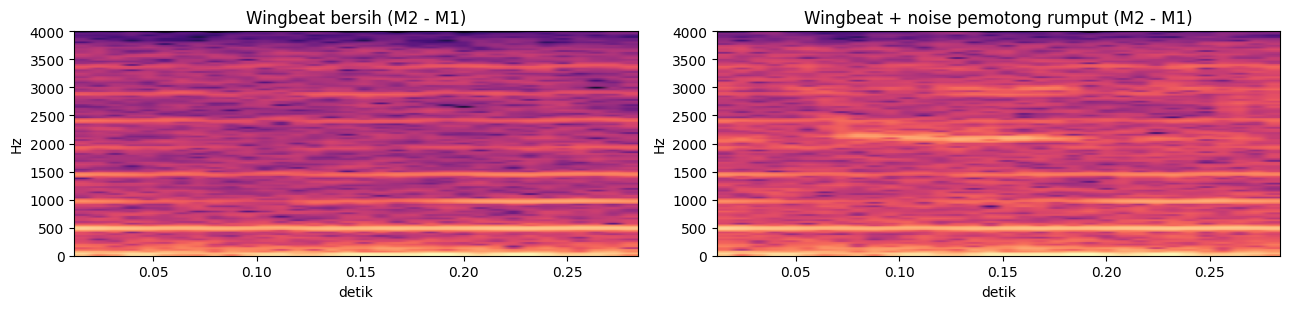

In [9]:
import matplotlib.pyplot as plt
noise, noise_names = load_noise('data/environmental_noise_recordings')
print(f'N-OUTDOOR: {len(noise)} file, {sum(len(a) for a, _ in noise)/SR:.2f} s (paper Tabel 2: 164.04 s)')
print(f'Geometri: d1 = {D1:.3f} m, d2 = {D2:.3f} m, delay M1 = {DELAY1}, M2 = {DELAY2} sampel')

# Contoh satu epoch: bersih vs ber-noise setelah cancellation (G = 1)
x = split_fold(E, totals, 0)['test'][0][0]
clean = mosquito_cancelled(x[None], 1)[0]
n1, n2 = noise[noise_names.index('30cm_grasscutting_normalized_16bit.wav')]
noisy = clean + (n2[8000:8000 + TARGET] - n1[8000:8000 + TARGET])
fig, ax = plt.subplots(1, 2, figsize=(13, 3.2))
for a, (title, s) in zip(ax, [('Wingbeat bersih (M2 - M1)', clean), ('Wingbeat + noise pemotong rumput (M2 - M1)', noisy)]):
    a.specgram(s, Fs=SR, NFFT=256, noverlap=192, cmap='magma'); a.set(title=title, xlabel='detik', ylabel='Hz')
plt.tight_layout(); plt.show()

## 5. Analisis Data Eksploratif (EDA)

Sebelum melatih model, bagian ini memeriksa karakteristik data supaya keputusan pemodelan punya dasar. Semua analisis berjalan di CPU dan hanya membaca data (tidak ada yang mengubah input training).

| Sub-bagian | Pertanyaan yang dijawab |
|---|---|
| 5.1 Inventaris file | Berapa rekaman per kelas, mikrofon, umur nyamuk? Format audio seragam? |
| 5.2 Epoch dan keseimbangan kelas | Seberapa tidak seimbang kelasnya setelah dipotong 300 ms? |
| 5.3 Kualitas sinyal | Level amplitudo, clipping, DC offset per kelas dan mikrofon |
| 5.4 Contoh sinyal | Seperti apa waveform dan spektrogram tiap kelas? |
| 5.5 Frekuensi dasar (F0) dan harmonik | Apakah kelas bisa dibedakan dari F0 saja? Kelas mana yang tumpang tindih? |
| 5.6 Spektrum rata-rata | Di pita frekuensi mana informasi berada? Beda mikrofon? |
| 5.7 Faktor umur dan mikrofon | Seberapa besar variasi di dalam satu kelas? |
| 5.8 Noise lingkungan dan SNR | Seberapa berat noise pada test, dan berapa contoh test yang benar-benar ber-noise? |
| 5.9 Efek simulasi 2 mikrofon | Bagaimana noise cancellation M2 − M1 mengubah spektrum wingbeat? |
| 5.10 Split fold dan kebocoran | Distribusi kelas per fold dan berapa epoch test yang berasal dari file yang juga ada di train |
| 5.11 Proyeksi 2D | Apakah kelas membentuk klaster terpisah di ruang fitur spektral? |
| 5.12 Ringkasan | Angka kunci dan implikasinya bagi model |

1324 file | format (sr, kanal, subtype): {(8000, 1, 'PCM_16'): np.int64(1324)} | suhu: ['25C'] | wadah: ['SmallCylinder'] | total durasi 43.7 menit


jumlah file              durasi (detik)                
mikrofon    Kondenser LowMic total      Kondenser  LowMic   total
kelas                                                            
Ae.aeg F           83     83   166          145.8   145.8   291.6
Ae.aeg M           98     98   196          154.8   154.8   309.6
Ae.alb F           91     91   182          163.7   164.5   328.2
Ae.alb M          110    108   218          188.9   180.9   369.7
An.dir F          102     50   152          174.7    63.0   237.6
An.dir M          122     56   178          128.9    59.6   188.5
Cx.quin F          77     43   120          216.5   162.0   378.5
Cx.quin M          66     46   112          385.8   132.4   518.2
total             749    575  1324         1559.1  1062.9  2622.0

file  durasi_s  durasi_median_s
kelas     umur mikrofon                                  
Ae.aeg F  21D  Kondenser    37     38.51             0.88
               LowMic       37     38.51             0.88
          5D   Kondenser    46    107.28             2.01
               LowMic       46    107.29             2.01
Ae.aeg M  21D  Kondenser    44     69.61             1.48
               LowMic       44     69.61             1.48
          5D   Kondenser    54     85.19             1.41
               LowMic       54     85.19             1.41
Ae.alb F  14D  Kondenser    35     73.16             1.18
               LowMic       35     73.40             1.18
          7D   Kondenser    56     90.56             1.46
               LowMic       56     91.11             1.45
Ae.alb M  14D  Kondenser    44     98.57             1.89
               LowMic       45     96.90             1.88
          7D   Kondenser    66     90.29             1.20
               LowMic       63     83.96             1.18
An.dir F  14D  Kondenser    59    102.74             1.26
               LowMic       50     62.98             1.04
          5D   Kondenser    43     71.93             1.11
An.dir M  14D  Kondenser    71     69.68             0.85
               LowMic       56     59.61             0.92
          5D   Kondenser    51     59.21             1.11
Cx.quin F 14D  Kondenser    36    155.29             1.82
               LowMic       43    162.01             1.41
          6D   Kondenser    41     61.22             1.41
Cx.quin M 14D  Kondenser    42    118.80             1.63
               LowMic       46    132.36             1.62
          6D   Kondenser    24    267.05             4.60

File LowMic dengan kembaran kondenser (durasi sama): 303 dari 575 -> kejadian wingbeat ini direkam dua kali oleh dua mikrofon


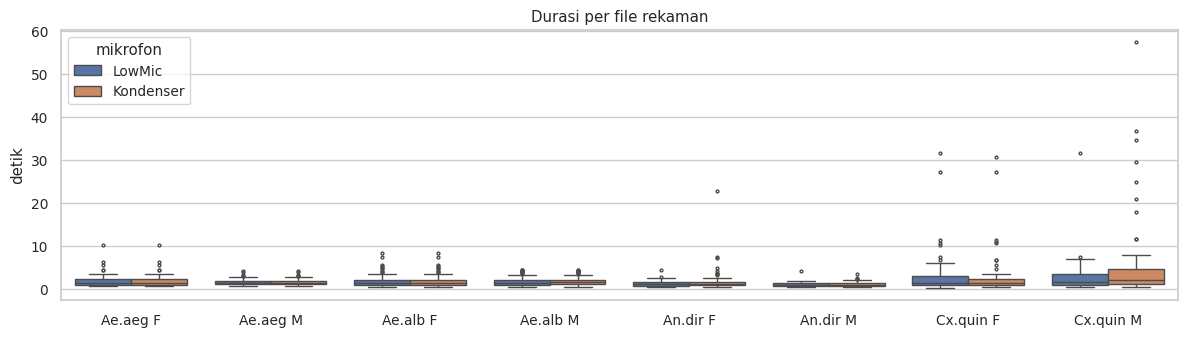

In [10]:
# 5.1 Inventaris file rekaman
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

DATA_DIR = 'data/mosquito_recordings'
os.makedirs('figures', exist_ok=True)
sns.set_theme(style='whitegrid', font_scale=0.9)
PAL = dict(zip(SHORT, sns.color_palette('tab10', 8)))


def parse_name(fn):
    """Spesies_<n><sex>_<umur>_<suhu>_<wadah>[_LowMic]_cut<k>_16bit.wav -> metadata."""
    r = fn.split('_')
    sex = r[1].strip()[-1]
    return {'file': fn, 'spesies': r[0], 'sex': sex, 'umur': r[2].strip(), 'suhu': r[3], 'wadah': r[4],
            'mikrofon': 'LowMic' if r[5] == 'LowMic' else 'Kondenser',
            'kelas': SHORT[CLASSES.index(f'{r[0]}_{sex}')], 'kelompok': group_key(r)}


files = [f for f in sorted(os.listdir(DATA_DIR), key=numerical_sort) if f.endswith('.wav') and not f.startswith('An.Minimus')]
info = {f: sf.info(os.path.join(DATA_DIR, f)) for f in files}
inv = pd.DataFrame([{**parse_name(f), 'durasi_s': info[f].frames / SR} for f in files])
fmt = pd.Series([(i.samplerate, i.channels, i.subtype) for i in info.values()]).value_counts()
print(f'{len(inv)} file | format (sr, kanal, subtype): {dict(fmt)} | suhu: {sorted(inv.suhu.unique())} | '
      f'wadah: {sorted(inv.wadah.unique())} | total durasi {inv.durasi_s.sum()/60:.1f} menit')

display(pd.concat({'jumlah file': inv.pivot_table(index='kelas', columns='mikrofon', values='file', aggfunc='count',
                                                   margins=True, margins_name='total', fill_value=0),
                   'durasi (detik)': inv.pivot_table(index='kelas', columns='mikrofon', values='durasi_s', aggfunc='sum',
                                                      margins=True, margins_name='total', fill_value=0).round(1)}, axis=1)
        .reindex(SHORT + ['total']))
display(inv.groupby(['kelas', 'umur', 'mikrofon']).agg(file=('file', 'count'), durasi_s=('durasi_s', 'sum'),
                                                       durasi_median_s=('durasi_s', 'median')).round(2))

# Rekaman kembar: file LowMic yang punya pasangan file kondenser dengan nama & durasi sama (direkam bersamaan)
twin_key = lambda f: f.replace('_LowMic', '').lower()
cond = inv[inv.mikrofon == 'Kondenser'].assign(k=lambda d: d.file.map(twin_key)).set_index('k').durasi_s
low = inv[inv.mikrofon == 'LowMic'].assign(k=lambda d: d.file.map(twin_key))
has_twin = low.k.isin(cond.index) & np.isclose(low.durasi_s, cond.reindex(low.k).values, atol=0.05)
print(f'File LowMic dengan kembaran kondenser (durasi sama): {has_twin.sum()} dari {len(low)} '
      f'-> kejadian wingbeat ini direkam dua kali oleh dua mikrofon')

fig, ax = plt.subplots(figsize=(12, 3.5))
sns.boxplot(data=inv, x='kelas', y='durasi_s', hue='mikrofon', order=SHORT, ax=ax, fliersize=2)
ax.set(title='Durasi per file rekaman', xlabel='', ylabel='detik')
plt.tight_layout(); plt.savefig('figures/eda_durasi_file.png', dpi=130); plt.show()

mikrofon,Kondenser,LowMic,total,% dari data
kelas,,,,
Ae.aeg F,841,841,1682,10.9
Ae.aeg M,881,881,1762,11.4
Ae.alb F,947,956,1903,12.3
Ae.alb M,1090,1038,2128,13.8
An.dir F,1011,346,1357,8.8
An.dir M,665,308,973,6.3
Cx.quin F,1327,1012,2339,15.2
Cx.quin M,2469,808,3277,21.3


Rasio ketidakseimbangan (kelas terbesar / terkecil): 3.37 (Cx.quin M vs An.dir M); LowMic = 40.1 % epoch


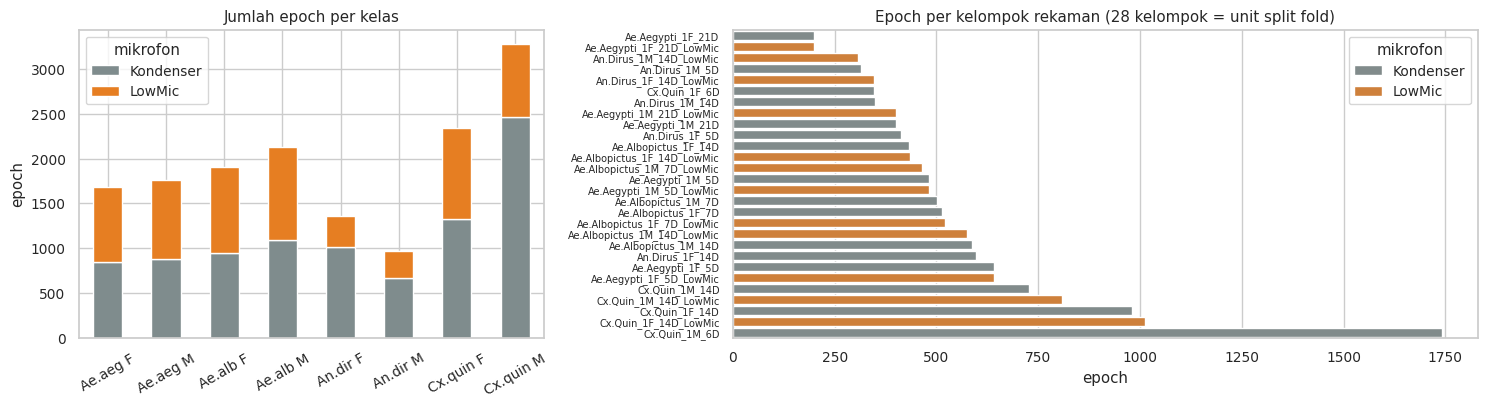

In [11]:
# 5.2 Epoch 300 ms per kelas, mikrofon, dan kelompok rekaman
E_files = epoch_files(DATA_DIR)                        # urutan identik dengan E (load_epochs)
assert len(E_files) == len(E)
meta = inv.set_index('file').loc[E_files].reset_index()
meta['idx'] = np.arange(len(meta))

ep = meta.groupby(['kelas', 'mikrofon']).size().unstack(fill_value=0).reindex(SHORT)
ep['total'] = ep.sum(1)
ep['% dari data'] = (100 * ep.total / ep.total.sum()).round(1)
display(ep)
print(f'Rasio ketidakseimbangan (kelas terbesar / terkecil): {ep.total.max() / ep.total.min():.2f} '
      f'({ep.total.idxmax()} vs {ep.total.idxmin()}); LowMic = {100 * ep.LowMic.sum() / ep.total.sum():.1f} % epoch')

grp = meta.groupby(['kelompok', 'kelas', 'mikrofon']).agg(file=('file', 'nunique'), epoch=('idx', 'count')).reset_index()
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={'width_ratios': [1, 1.6]})
ep[['Kondenser', 'LowMic']].plot.bar(stacked=True, ax=ax[0], color=['#7f8c8d', '#e67e22'])
ax[0].set(title='Jumlah epoch per kelas', xlabel='', ylabel='epoch'); ax[0].tick_params(axis='x', rotation=30)
sns.barplot(data=grp.sort_values('epoch'), y='kelompok', x='epoch', hue='mikrofon', dodge=False, ax=ax[1],
            palette={'Kondenser': '#7f8c8d', 'LowMic': '#e67e22'})
ax[1].set(title=f'Epoch per kelompok rekaman ({len(grp)} kelompok = unit split fold)', ylabel='')
ax[1].tick_params(axis='y', labelsize=7)
plt.tight_layout(); plt.savefig('figures/eda_epoch_kelas.png', dpi=130); plt.show()

RMS (dBFS)  puncak (dBFS)  crest factor (dB)  \
kelas     mikrofon                                                  
Ae.aeg F  Kondenser  -47.429001     -35.160999             12.574   
          LowMic     -38.138000     -27.448999             10.602   
Ae.aeg M  Kondenser  -48.894001     -35.848000             13.039   
          LowMic     -38.654999     -26.325001             11.090   
Ae.alb F  Kondenser  -50.388000     -38.758999             11.566   
          LowMic     -43.112000     -32.971001              9.660   
Ae.alb M  Kondenser  -50.912998     -39.354000             11.710   
          LowMic     -42.823002     -33.126999              9.458   
An.dir F  Kondenser  -50.827999     -39.075001             10.942   
          LowMic     -34.872002     -23.482000             10.567   
An.dir M  Kondenser  -55.180000     -43.948002             11.069   
          LowMic     -43.234001     -32.534000              9.721   
Cx.quin F Kondenser  -49.908001     -38.096001             11.524   
          LowMic     -38.812000     -28.184999              9.888   
Cx.quin M Kondenser  -50.787998     -38.922001             11.713   
          LowMic     -40.245998     -30.902000              9.855   

                     clipping (%)  DC offset  
kelas     mikrofon                            
Ae.aeg F  Kondenser           0.0     -0.000  
          LowMic              0.0     -0.002  
Ae.aeg M  Kondenser           0.0     -0.000  
          LowMic              0.0     -0.002  
Ae.alb F  Kondenser           0.0     -0.000  
          LowMic              0.0     -0.000  
Ae.alb M  Kondenser           0.0     -0.000  
          LowMic              0.0     -0.000  
An.dir F  Kondenser           0.0     -0.000  
          LowMic              0.0     -0.000  
An.dir M  Kondenser           0.0     -0.000  
          LowMic              0.0     -0.001  
Cx.quin F Kondenser           0.0     -0.000  
          LowMic              0.0     -0.000  
Cx.quin M Kondenser           0.0     -0.000  
          LowMic              0.0     -0.000

File dengan clipping > 0,1 %: 0 dari 1324; |DC offset| maks: 0.0650


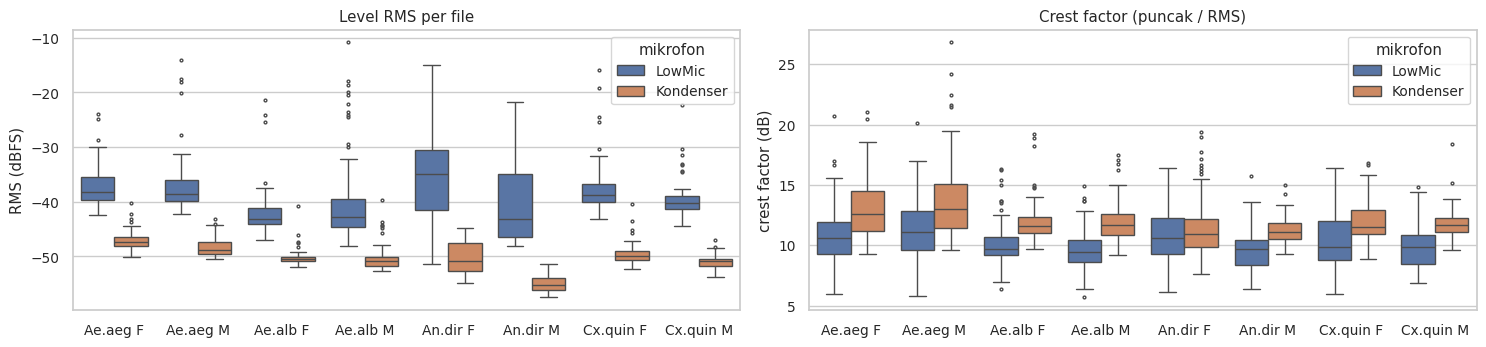

In [12]:
# 5.3 Kualitas sinyal per file: level RMS, puncak, clipping, DC offset
def file_stats(fn):
    x, _ = sf.read(os.path.join(DATA_DIR, fn), dtype='float32')
    rms = np.sqrt(np.mean(x ** 2)) + 1e-12
    return {'file': fn, 'RMS (dBFS)': 20 * np.log10(rms), 'puncak (dBFS)': 20 * np.log10(np.abs(x).max() + 1e-12),
            'crest factor (dB)': 20 * np.log10((np.abs(x).max() + 1e-12) / rms),
            'clipping (%)': 100 * np.mean(np.abs(x) >= 0.999), 'DC offset': float(x.mean())}


qual = inv.merge(pd.DataFrame([file_stats(f) for f in files]), on='file')
display(qual.groupby(['kelas', 'mikrofon'])[['RMS (dBFS)', 'puncak (dBFS)', 'crest factor (dB)', 'clipping (%)', 'DC offset']]
        .median().reindex(SHORT, level=0).round(3))
print(f"File dengan clipping > 0,1 %: {(qual['clipping (%)'] > 0.1).sum()} dari {len(qual)}; "
      f"|DC offset| maks: {qual['DC offset'].abs().max():.4f}")

fig, ax = plt.subplots(1, 2, figsize=(15, 3.6))
sns.boxplot(data=qual, x='kelas', y='RMS (dBFS)', hue='mikrofon', order=SHORT, ax=ax[0], fliersize=2)
sns.boxplot(data=qual, x='kelas', y='crest factor (dB)', hue='mikrofon', order=SHORT, ax=ax[1], fliersize=2)
ax[0].set(title='Level RMS per file', xlabel=''); ax[1].set(title='Crest factor (puncak / RMS)', xlabel='')
plt.tight_layout(); plt.savefig('figures/eda_kualitas_sinyal.png', dpi=130); plt.show()

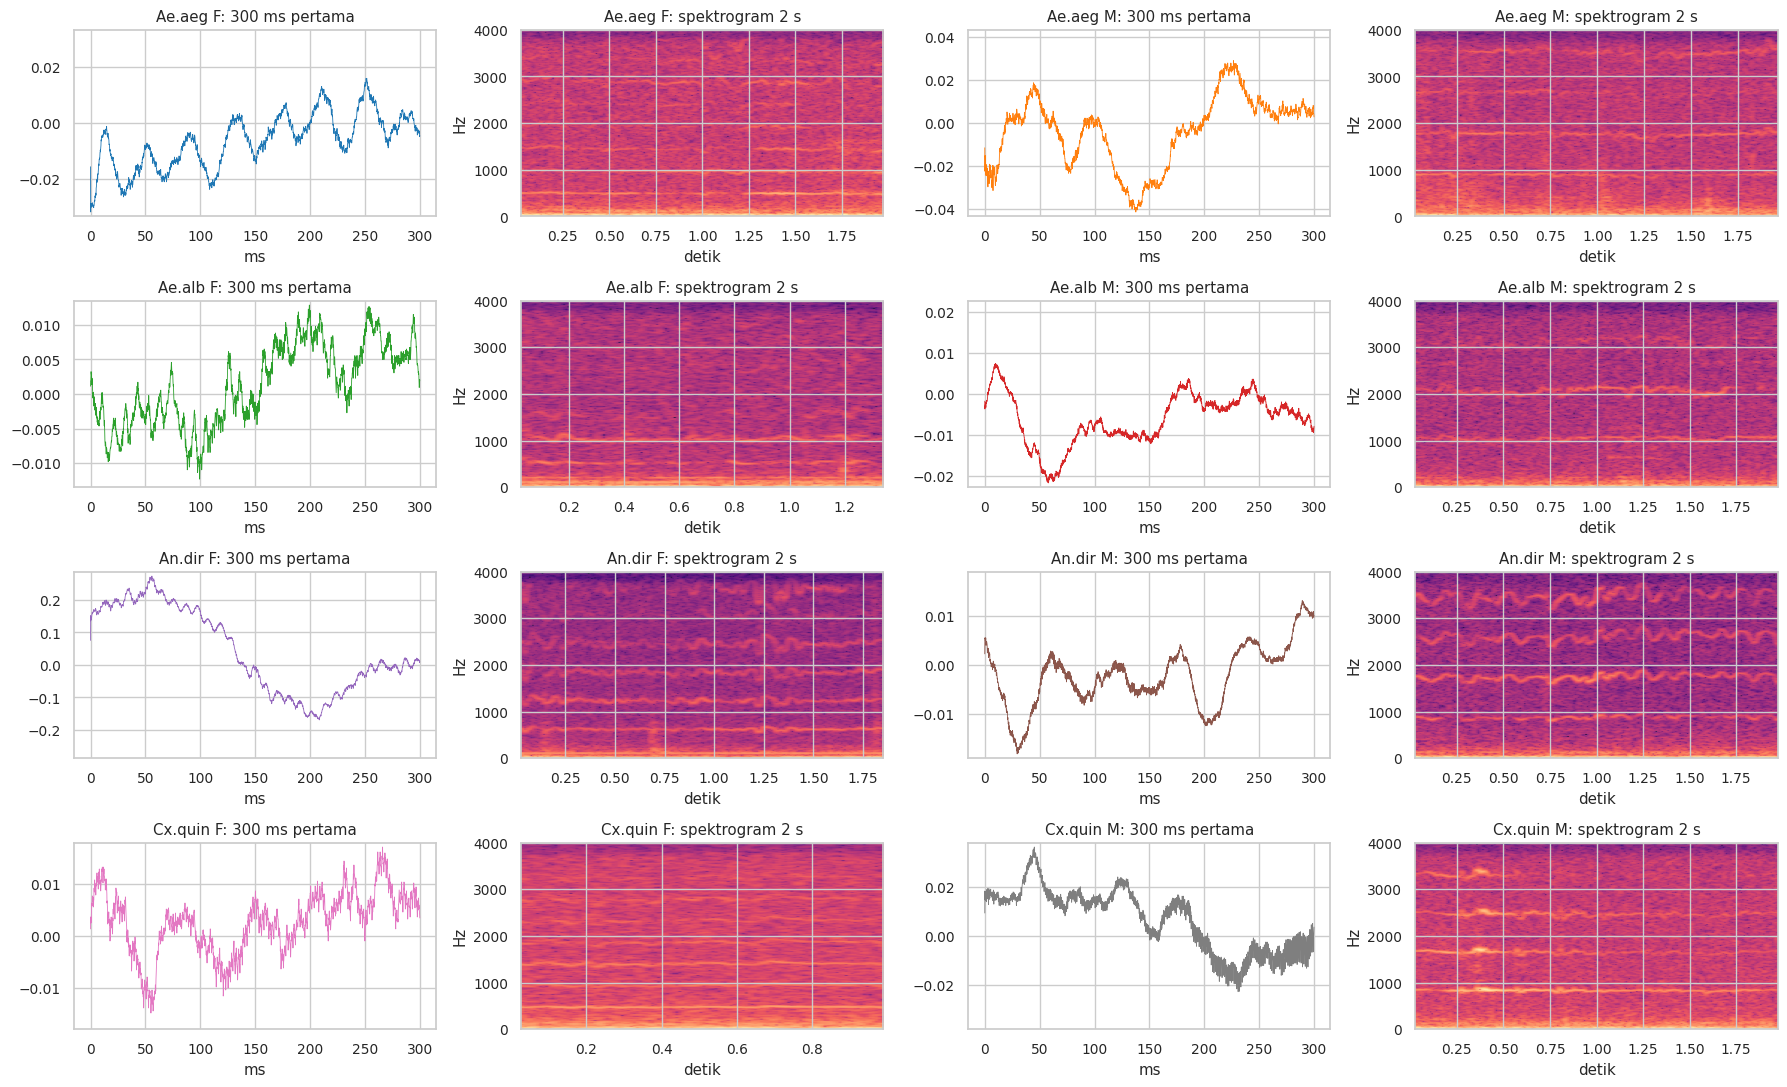

In [13]:
# 5.4 Contoh waveform 300 ms dan spektrogram rekaman per kelas (mikrofon LowMic, seperti test)
fig, axes = plt.subplots(4, 4, figsize=(18, 11))
for k, cls in enumerate(SHORT):
    fn = inv[(inv.kelas == cls) & (inv.mikrofon == 'LowMic')].file.iloc[0]
    x, _ = sf.read(os.path.join(DATA_DIR, fn), dtype='float32')
    a_wav, a_spec = axes[k // 2, (k % 2) * 2], axes[k // 2, (k % 2) * 2 + 1]
    seg = x[:TARGET]
    a_wav.plot(np.arange(TARGET) / SR * 1000, seg, lw=.6, color=PAL[cls])
    a_wav.set(title=f'{cls}: 300 ms pertama', xlabel='ms', ylim=(-1.05 * np.abs(seg).max(), 1.05 * np.abs(seg).max()))
    a_spec.specgram(x[:min(len(x), 2 * SR)], Fs=SR, NFFT=512, noverlap=448, cmap='magma')
    a_spec.set(title=f'{cls}: spektrogram 2 s', xlabel='detik', ylabel='Hz', ylim=(0, 4000))
plt.tight_layout(); plt.savefig('figures/eda_contoh_kelas.png', dpi=120); plt.show()

,count,10%,25%,50%,75%,90%
kelas,,,,,,
Ae.aeg F,1682.0,476.0,487.0,501.0,516.0,562.0
Ae.aeg M,1762.0,255.0,268.0,339.0,831.0,865.0
Ae.alb F,1903.0,403.0,547.0,562.0,597.0,609.0
Ae.alb M,2128.0,267.0,327.0,990.0,1023.0,1101.0
An.dir F,1357.0,288.0,551.0,581.0,601.0,619.0
An.dir M,973.0,267.0,281.0,435.0,847.0,869.0
Cx.quin F,2339.0,442.0,449.0,457.0,470.0,497.0
Cx.quin M,3277.0,273.0,296.0,691.0,814.0,838.0


Persentase epoch dengan F0 terdeteksi < 450 Hz, per kelas dan umur:


umur,14D,21D,5D,6D,7D
kelas,,,,,
Ae.aeg F,NaN,15.6,5.7,NaN,NaN
Ae.aeg M,NaN,62.3,48.0,NaN,NaN
Ae.alb F,6.2,NaN,NaN,NaN,13.8
Ae.alb M,38.6,NaN,NaN,NaN,45.8
An.dir F,17.9,NaN,31.4,NaN,NaN
An.dir M,30.7,NaN,90.5,NaN,NaN
Cx.quin F,27.2,NaN,NaN,23.1,NaN
Cx.quin M,42.9,NaN,NaN,28.3,NaN


Pasangan kelas dengan distribusi F0 paling tumpang tindih:
  Ae.aeg M   vs An.dir M  : overlap 0.65
  Ae.alb F   vs An.dir F  : overlap 0.62
  An.dir M   vs Cx.quin M : overlap 0.50
  Ae.aeg M   vs Cx.quin M : overlap 0.48
  Ae.aeg F   vs Ae.alb F  : overlap 0.26


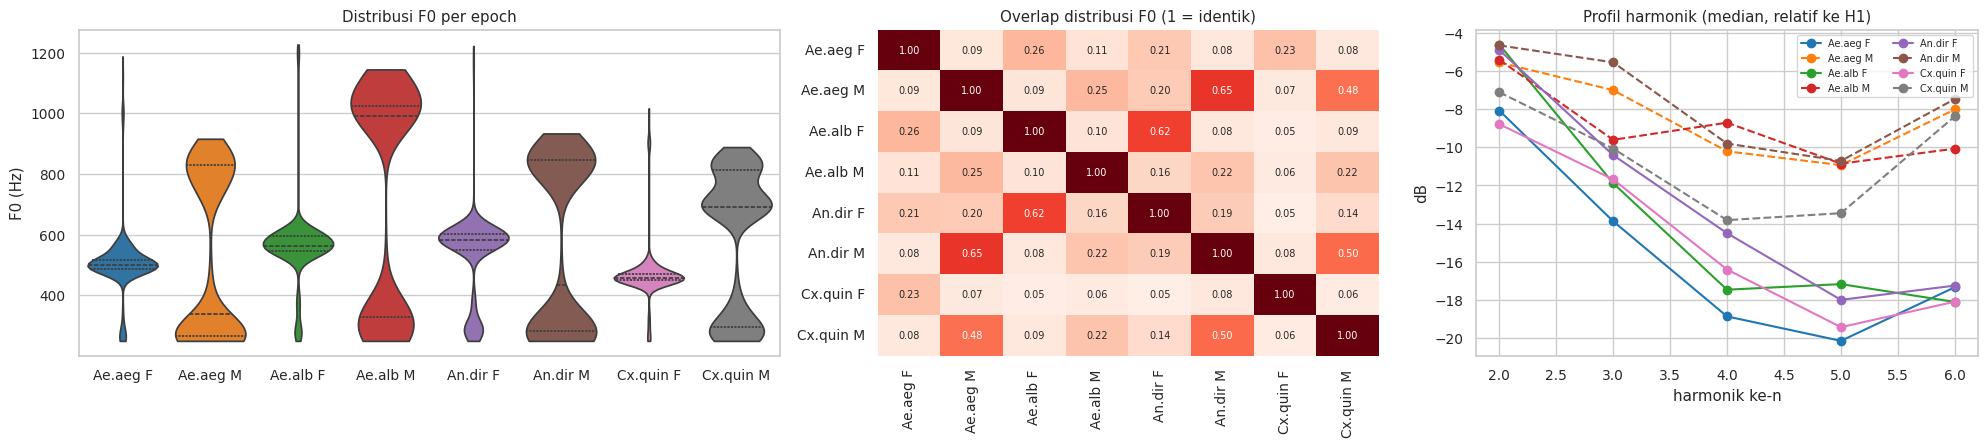

In [14]:
# 5.5 Frekuensi dasar (F0) dan profil harmonik per epoch
NFFT = 8192                                            # zero padding: resolusi 0,98 Hz
FREQ = np.fft.rfftfreq(NFFT, 1 / SR)
F0_BAND = (FREQ >= 250) & (FREQ <= 1300)               # rentang F0 nyamuk dewasa


def spectral_features(X, n_h=6, chunk=1500):
    """Per epoch: F0 (harmonic product spectrum, 3 harmonik), amplitudo harmonik 1..n_h relatif ke H1 (dB),
    spectral centroid, dan log-PSD (dB) untuk analisis spektrum rata-rata."""
    win = np.hanning(X.shape[1]).astype(np.float32)
    band_idx = np.where(F0_BAND)[0]
    f0, harm, cent, psd = [], [], [], []
    for i in range(0, len(X), chunk):
        x = X[i:i + chunk]
        S = np.abs(np.fft.rfft((x - x.mean(1, keepdims=True)) * win, NFFT)).astype(np.float32) + 1e-9
        logS = np.log(np.where(FREQ >= 150, S, 1e-9))     # abaikan rumble < 150 Hz saat mencari F0
        hps = logS[:, band_idx] + logS[:, 2 * band_idx] + logS[:, np.minimum(3 * band_idx, len(FREQ) - 1)]
        k0 = band_idx[hps.argmax(1)]
        f0.append(FREQ[k0])
        h = []
        for n in range(1, n_h + 1):                     # puncak di sekitar n*F0 (±3 %); NaN bila di atas Nyquist
            lo, hi = np.floor(n * k0 * 0.97).astype(int), np.ceil(n * k0 * 1.03).astype(int)
            v = np.full(len(x), np.nan, np.float32)
            for j in np.where(hi < len(FREQ))[0]:
                v[j] = S[j, lo[j]:hi[j] + 1].max()
            h.append(v)
        h = 20 * np.log10(np.array(h).T)
        harm.append(h - h[:, :1])
        P = S ** 2
        cent.append((P * FREQ).sum(1) / P.sum(1))
        psd.append(10 * np.log10(P[:, ::8]))            # 1025 titik (7,8 Hz) cukup untuk plot
    return np.concatenate(f0), np.concatenate(harm), np.concatenate(cent), np.concatenate(psd)


X_all = np.stack([e[3] for e in E])
F0, HARM, CENT, PSD = spectral_features(X_all)
FREQ_PSD = FREQ[::8]
meta['F0'], meta['centroid'] = F0, CENT

f0_tab = meta.groupby('kelas').F0.describe(percentiles=[.1, .25, .5, .75, .9]).reindex(SHORT)
display(f0_tab[['count', '10%', '25%', '50%', '75%', '90%']].round(0))

# Distribusi F0 jantan bimodal: sebagian epoch didominasi komponen nada ±270-450 Hz (tergantung file/kelompok)
meta['F0 < 450 Hz'] = meta.F0 < 450
mode_tab = meta.groupby(['kelas', 'umur'])['F0 < 450 Hz'].mean().unstack().reindex(SHORT).mul(100).round(1)
print('Persentase epoch dengan F0 terdeteksi < 450 Hz, per kelas dan umur:'); display(mode_tab)

# Tumpang tindih distribusi F0 antar kelas: overlap coefficient = Σ min(p_i, p_j) pada histogram 5 Hz
bins = np.arange(250, 1305, 5)
H = np.stack([np.histogram(meta.F0[meta.kelas == c], bins)[0] / (meta.kelas == c).sum() for c in SHORT])
OV = np.array([[np.minimum(H[i], H[j]).sum() for j in range(8)] for i in range(8)])
pairs = sorted(((OV[i, j], SHORT[i], SHORT[j]) for i in range(8) for j in range(i + 1, 8)), reverse=True)
print('Pasangan kelas dengan distribusi F0 paling tumpang tindih:')
for v, a, b in pairs[:5]:
    print(f'  {a:10s} vs {b:10s}: overlap {v:.2f}')

fig, ax = plt.subplots(1, 3, figsize=(20, 4.6), gridspec_kw={'width_ratios': [1.4, 1, 1]})
sns.violinplot(data=meta, x='kelas', y='F0', hue='kelas', order=SHORT, palette=PAL, cut=0, inner='quartile', legend=False, ax=ax[0])
ax[0].set(title='Distribusi F0 per epoch', xlabel='', ylabel='F0 (Hz)')
sns.heatmap(pd.DataFrame(OV, SHORT, SHORT), annot=True, fmt='.2f', cmap='Reds', vmin=0, vmax=1, cbar=False, ax=ax[1],
            annot_kws={'size': 7})
ax[1].set(title='Overlap distribusi F0 (1 = identik)')
hp = pd.DataFrame(HARM[:, 1:], columns=[f'H{n}' for n in range(2, HARM.shape[1] + 1)]).groupby(meta.kelas).median().reindex(SHORT)
for c in SHORT:
    ax[2].plot(range(2, HARM.shape[1] + 1), hp.loc[c], marker='o', label=c, color=PAL[c],
               ls='-' if c.endswith('F') else '--')
ax[2].set(title='Profil harmonik (median, relatif ke H1)', xlabel='harmonik ke-n', ylabel='dB'); ax[2].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig('figures/eda_f0_harmonik.png', dpi=130); plt.show()

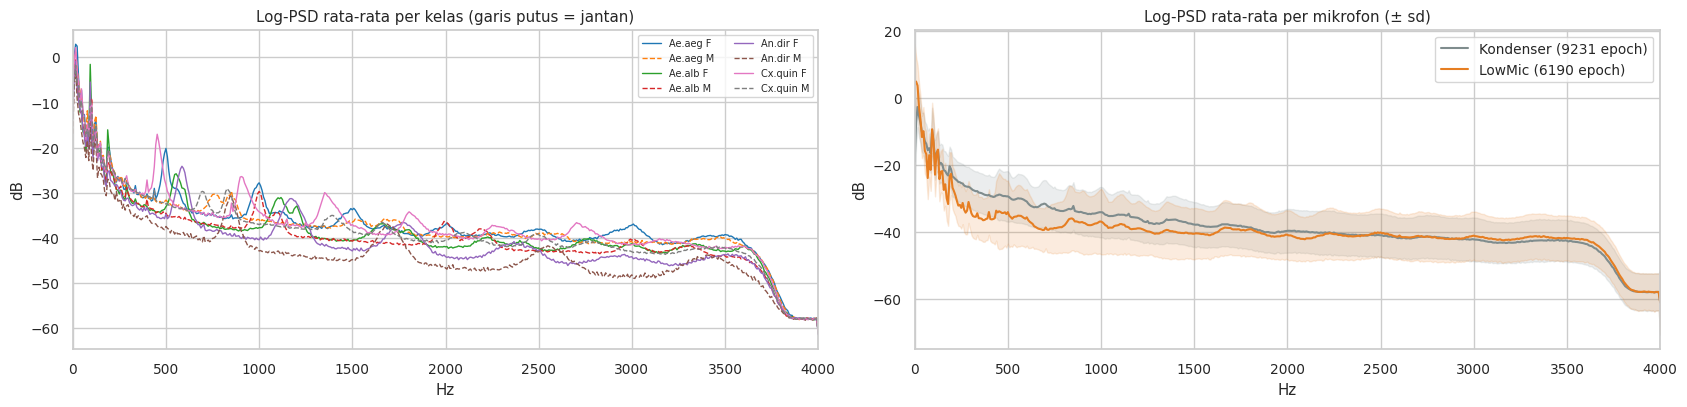

Porsi energi per pita frekuensi (% median per epoch):


,0-60 Hz,60-150 Hz,150-250 Hz,250-500 Hz,500-1000 Hz,1000-2000 Hz,2000-4000 Hz
kelas,,,,,,,
Ae.aeg F,85.099998,6.300000,0.9,1.3,1.7,0.8,0.4
Ae.aeg M,85.900002,8.200000,1.0,0.7,1.3,0.7,0.5
Ae.alb F,68.199997,19.600000,1.5,0.5,2.3,1.8,0.6
Ae.alb M,80.699997,12.100000,1.2,0.8,1.1,1.0,0.6
An.dir F,71.800003,18.500000,1.4,1.2,1.9,1.2,0.4
An.dir M,76.900002,12.600000,2.1,1.6,1.7,0.9,0.7
Cx.quin F,79.500000,7.900000,1.3,3.6,1.6,1.2,0.6
Cx.quin M,70.199997,17.799999,2.7,2.0,2.6,1.2,0.8


In [15]:
# 5.6 Spektrum rata-rata per kelas dan per jenis mikrofon
fig, ax = plt.subplots(1, 2, figsize=(17, 4.2))
for c in SHORT:
    m = (meta.kelas == c).values
    ax[0].plot(FREQ_PSD, PSD[m].mean(0), color=PAL[c], lw=1, ls='-' if c.endswith('F') else '--', label=c)
ax[0].set(title='Log-PSD rata-rata per kelas (garis putus = jantan)', xlabel='Hz', ylabel='dB', xlim=(0, 4000))
ax[0].legend(fontsize=7, ncol=2)
for mic, col in (('Kondenser', '#7f8c8d'), ('LowMic', '#e67e22')):
    m = (meta.mikrofon == mic).values
    mu, sd = PSD[m].mean(0), PSD[m].std(0)
    ax[1].plot(FREQ_PSD, mu, color=col, label=f'{mic} ({m.sum()} epoch)'); ax[1].fill_between(FREQ_PSD, mu - sd, mu + sd, color=col, alpha=.15)
ax[1].set(title='Log-PSD rata-rata per mikrofon (± sd)', xlabel='Hz', ylabel='dB', xlim=(0, 4000)); ax[1].legend()
plt.tight_layout(); plt.savefig('figures/eda_psd.png', dpi=130); plt.show()

band_edges = [0, 60, 150, 250, 500, 1000, 2000, 4000]
energy = pd.DataFrame({f'{lo}-{hi} Hz': (10 ** (PSD[:, (FREQ_PSD >= lo) & (FREQ_PSD < hi)] / 10)).sum(1)
                       for lo, hi in zip(band_edges[:-1], band_edges[1:])})
energy = 100 * energy.div(energy.sum(1), axis=0)
print('Porsi energi per pita frekuensi (% median per epoch):')
display(energy.groupby(meta.kelas).median().reindex(SHORT).round(1))

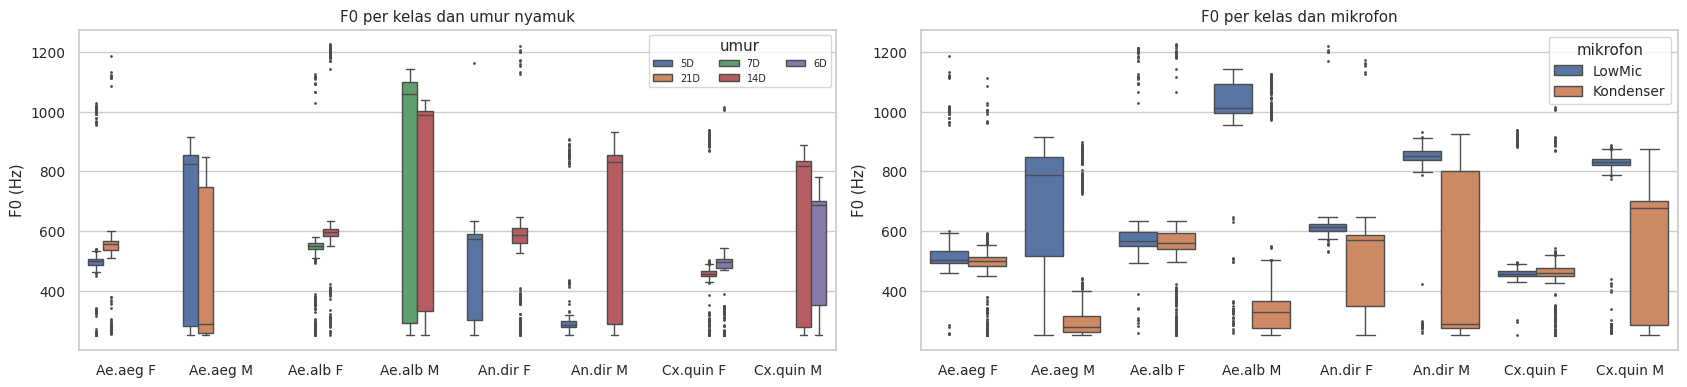

,sd F0 semua epoch (Hz),sd median F0 antar file (Hz),selisih median F0 antar umur (Hz)
kelas,,,
Ae.aeg F,109.3,65.4,56.6
Ae.aeg M,270.7,265.8,537.6
Ae.alb F,129.4,108.9,46.9
Ae.alb M,364.9,363.2,71.3
An.dir F,136.1,73.7,10.7
An.dir M,282.3,272.5,545.9
Cx.quin F,90.3,53.6,40.0
Cx.quin M,227.5,249.5,130.4


In [16]:
# 5.7 Variasi di dalam kelas: umur nyamuk dan jenis mikrofon
fig, ax = plt.subplots(1, 2, figsize=(17, 4))
sns.boxplot(data=meta, x='kelas', y='F0', hue='umur', order=SHORT, ax=ax[0], fliersize=1)
ax[0].set(title='F0 per kelas dan umur nyamuk', xlabel='', ylabel='F0 (Hz)'); ax[0].legend(fontsize=7, ncol=3, title='umur')
sns.boxplot(data=meta, x='kelas', y='F0', hue='mikrofon', order=SHORT, ax=ax[1], fliersize=1)
ax[1].set(title='F0 per kelas dan mikrofon', xlabel='', ylabel='F0 (Hz)')
plt.tight_layout(); plt.savefig('figures/eda_umur_mikrofon.png', dpi=130); plt.show()

within = meta.groupby('kelas').F0.std().reindex(SHORT)
between_rec = meta.groupby(['kelas', 'file']).F0.median().groupby('kelas').std().reindex(SHORT)
display(pd.DataFrame({'sd F0 semua epoch (Hz)': within, 'sd median F0 antar file (Hz)': between_rec,
                      'selisih median F0 antar umur (Hz)': meta.groupby(['kelas', 'umur']).F0.median().groupby('kelas')
                      .agg(lambda s: s.max() - s.min()).reindex(SHORT)}).round(1))

,file noise,durasi (s),RMS kanal (dBFS),korelasi antar kanal,reduksi oleh M2-M1 (dB),centroid M2-M1 (Hz)
0,30cm_GrassCutterFrontBroom,26.21,-27.010000,1.00,-38.169998,3519.87
1,30cm_GrassCutter,11.89,-26.120001,1.00,-39.080002,3515.58
2,30cm_animals,14.59,-32.040001,0.51,0.030000,330.59
3,30cm_broom,19.40,-30.400000,1.00,-34.720001,3517.88
4,30cm_grasscutting,22.89,-19.580000,0.89,-6.120000,353.73
5,30cm_motorcycle,19.07,-25.889999,0.87,-4.890000,232.20
6,30cm_watering2,33.40,-27.680000,1.00,-37.490002,3516.82
7,30cm_watering,10.58,-24.219999,1.00,-40.869999,3522.35
8,BioQuip CDC 30cm low,0.40,-19.900000,0.62,-0.940000,273.30
9,BioQuip CDC 30cm top,1.30,-18.559999,0.71,-2.260000,387.60


Set "noisy" yang benar-benar ber-noise: 48.5 % -> di test akhir (noisy + clean) hanya 24.2 % contoh ber-noise


,count,mean,std,min,10%,50%,90%,max
G,,,,,,,,
1.0,600.0,26.6,20.1,-6.1,1.9,17.8,50.8,68.4
1.5,600.0,30.1,20.1,-2.5,5.5,21.3,54.3,71.9
2.0,600.0,32.6,20.1,-0.0,8.0,23.8,56.8,74.4


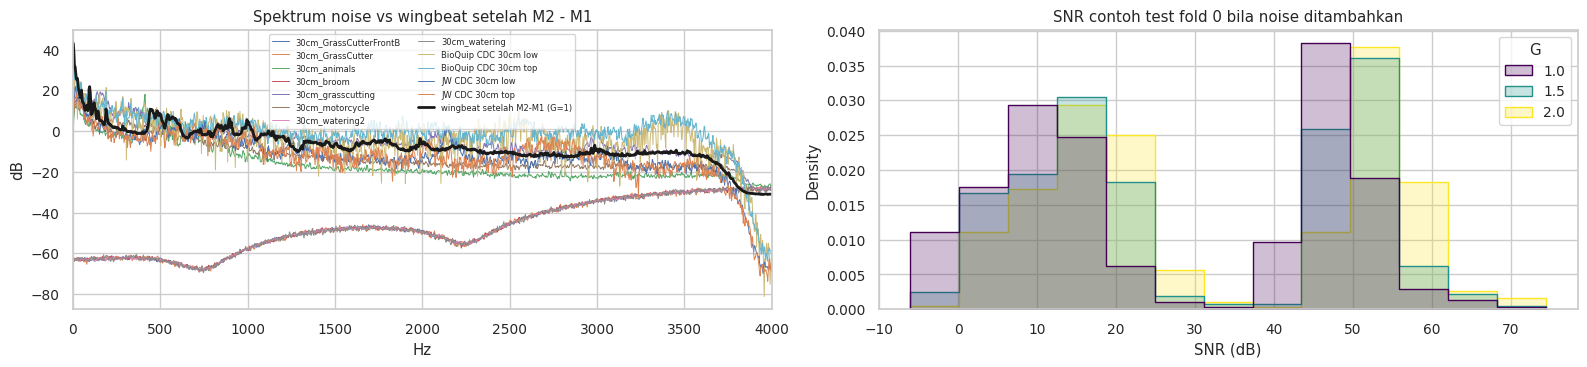

In [17]:
# 5.8 Noise lingkungan N-OUTDOOR dan SNR pada test
def overlay_noise_part(n_sig, seed, noise):
    """Rekonstruksi bagian noise (n2 - n1) yang dipakai overlay_one untuk seed tertentu."""
    random.seed(seed)
    n1, n2 = noise[random.randint(0, len(noise) - 1)]
    random.seed(seed)
    start = int(round(random.uniform(0, len(n1) - TARGET), 0))
    return n2[start:start + TARGET] - n1[start:start + TARGET]


rows = []
for name, (n1, n2) in zip(noise_names, noise):
    p1, p2, pd_ = np.mean(n1 ** 2), np.mean(n2 ** 2), np.mean((n2 - n1) ** 2)
    S = np.abs(np.fft.rfft(n2 - n1)) ** 2
    f = np.fft.rfftfreq(len(n1), 1 / SR)
    rows.append({'file noise': name.replace('_normalized_16bit.wav', ''), 'durasi (s)': len(n1) / SR,
                 'RMS kanal (dBFS)': 10 * np.log10((p1 + p2) / 2), 'korelasi antar kanal': np.corrcoef(n1, n2)[0, 1],
                 'reduksi oleh M2-M1 (dB)': 10 * np.log10(pd_ / ((p1 + p2) / 2)),
                 'centroid M2-M1 (Hz)': (S * f).sum() / S.sum()})
noise_tab = pd.DataFrame(rows)
display(noise_tab.round(2))

# SNR (dB) contoh test fold 0: sinyal wingbeat setelah cancellation vs noise setelah cancellation
Xte0 = split_fold(E, totals, 0)['test'][0]
snr, noisy_flag = [], []
for g in GAINS:
    for i, x in enumerate(Xte0):
        sig = mosquito_cancelled(x[None], g)[0]
        nz = overlay_noise_part(len(x), i, noise)
        snr.append({'G': g, 'SNR (dB)': 10 * np.log10(np.mean(sig ** 2) / (np.mean(nz ** 2) + 1e-12))})
        noisy_flag.append(not np.allclose(overlay_one(x, g, i, noise), sig))
snr = pd.DataFrame(snr)
print(f'Set "noisy" yang benar-benar ber-noise: {100 * np.mean(noisy_flag):.1f} % '
      f'-> di test akhir (noisy + clean) hanya {50 * np.mean(noisy_flag):.1f} % contoh ber-noise')
display(snr.groupby('G')['SNR (dB)'].describe(percentiles=[.1, .5, .9]).round(1))

def welch_db(sig2d):
    """PSD rata-rata (dB) dari potongan 300 ms berjendela Hann; skala sama untuk noise dan wingbeat."""
    return 10 * np.log10((np.abs(np.fft.rfft(sig2d * np.hanning(TARGET), axis=1)) ** 2).mean(0) + 1e-12)


f_w = np.fft.rfftfreq(TARGET, 1 / SR)
fig, ax = plt.subplots(1, 2, figsize=(16, 3.8))
for name, (n1, n2) in zip(noise_names, noise):
    d = n2 - n1
    ax[0].plot(f_w, welch_db(d[:len(d) // TARGET * TARGET].reshape(-1, TARGET)), lw=.7,
               label=name.replace('_normalized_16bit.wav', '')[:22])
ax[0].plot(f_w, welch_db(mosquito_cancelled(X_all[::10], 1)), color='k', lw=2, label='wingbeat setelah M2-M1 (G=1)')
ax[0].set(title='Spektrum noise vs wingbeat setelah M2 - M1', xlabel='Hz', ylabel='dB', xlim=(0, 4000)); ax[0].legend(fontsize=6, ncol=2)
sns.histplot(data=snr, x='SNR (dB)', hue='G', element='step', stat='density', common_norm=False, ax=ax[1], palette='viridis')
ax[1].set(title='SNR contoh test fold 0 bila noise ditambahkan')
plt.tight_layout(); plt.savefig('figures/eda_noise_snr.png', dpi=130); plt.show()

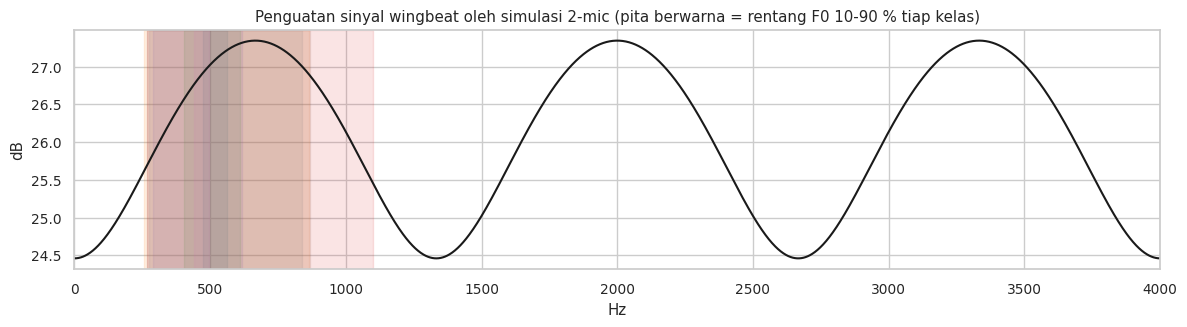

Penguatan di 500 Hz: 27.0 dB, di 1000 Hz: 26.1 dB, di 2000 Hz: 27.3 dB; minimum di 4000 Hz


In [18]:
# 5.9 Respons frekuensi simulasi 2 mikrofon + noise cancellation (M2 - M1) untuk sinyal wingbeat
f = np.linspace(0, SR / 2, 2001)
w = 2 * np.pi * f / SR
H_resp = np.abs(1 / D2 * np.exp(-1j * w * DELAY2) - 1 / D1 * np.exp(-1j * w * DELAY1))   # untuk G = 1
fig, ax = plt.subplots(figsize=(12, 3.4))
ax.plot(f, 20 * np.log10(H_resp), color='k')
for c in SHORT:
    q = meta.F0[meta.kelas == c].quantile([.1, .9])
    ax.axvspan(q.iloc[0], q.iloc[1], color=PAL[c], alpha=.12)
ax.set(title='Penguatan sinyal wingbeat oleh simulasi 2-mic (pita berwarna = rentang F0 10-90 % tiap kelas)',
       xlabel='Hz', ylabel='dB', xlim=(0, 4000))
plt.tight_layout(); plt.savefig('figures/eda_respons_2mic.png', dpi=130); plt.show()
print(f'Penguatan di 500 Hz: {20*np.log10(H_resp[np.argmin(abs(f-500))]):.1f} dB, di 1000 Hz: '
      f'{20*np.log10(H_resp[np.argmin(abs(f-1000))]):.1f} dB, di 2000 Hz: {20*np.log10(H_resp[np.argmin(abs(f-2000))]):.1f} dB; '
      f'minimum di {f[1:][np.argmin(H_resp[1:])]:.0f} Hz')

kelas,Ae.aeg F,Ae.aeg M,Ae.alb F,Ae.alb M,An.dir F,An.dir M,Cx.quin F,Cx.quin M
fold,,,,,,,,
0,83,87,94,103,34,30,97,72
1,83,87,94,103,34,30,97,72
2,83,87,94,103,34,30,97,72
3,83,87,94,103,34,30,97,72
4,83,87,94,103,34,30,97,72
5,83,87,94,103,34,30,97,72
6,83,87,94,103,34,30,97,72
7,83,87,94,103,34,30,97,72
8,83,87,94,103,34,30,97,72


,epoch test,test dari file yang juga di train,test yang rekaman kembarnya (kondenser) di train,test LowMic (%),test fold k = val fold k+1,bocor (%)
fold,,,,,,
0,600,135,144,100.0,600,22.5
1,600,186,211,100.0,600,31.0
2,600,141,265,100.0,600,23.5
3,600,112,149,100.0,600,18.7
4,600,163,163,100.0,600,27.2
5,600,135,63,100.0,600,22.5
6,600,163,78,100.0,600,27.2
7,600,168,128,100.0,600,28.0
8,600,201,126,100.0,600,33.5


Total: 1476 dari 6000 epoch test (24.6 %) berasal dari file yang juga ada di train fold yang sama -> analisis akhir juga dihitung pada subset bebas-kebocoran.


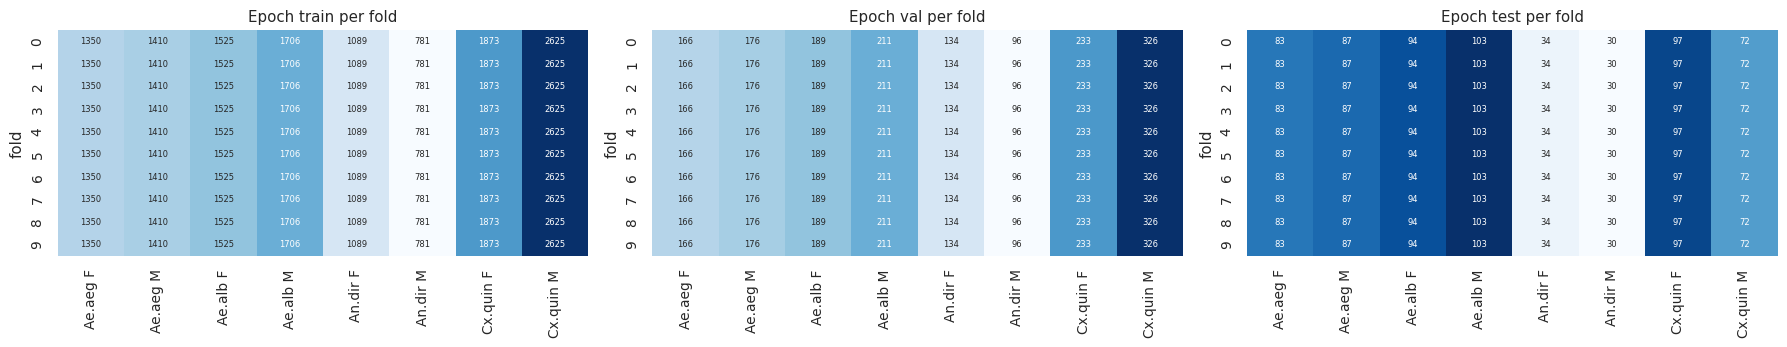

In [19]:
# 5.10 Distribusi kelas per fold dan kebocoran antar rekaman
E_idx = [(k, lab, low, np.array([i], dtype=np.float64)) for i, (k, lab, low, _) in enumerate(E)]   # split indeks, bukan sinyal
rows, leak_rows = [], []
for k in range(10):
    s = split_fold(E_idx, totals, k)
    idx = {part: s[part][0][:, 0].astype(int) for part in ('train', 'val', 'test')}
    for part in ('train', 'val', 'test'):
        for c, n in meta.iloc[idx[part]].kelas.value_counts().items():
            rows.append({'fold': k, 'bagian': part, 'kelas': c, 'epoch': n})
    train_files = set(meta.file.values[idx['train']])
    te_files = meta.file.values[idx['test']]
    nxt = split_fold(E_idx, totals, k + 1)['val'][0][:, 0].astype(int) if k < 9 else np.array([], int)
    twin = lambda f: f.replace('_LowMic', '').lower()       # rekaman yang sama dari mikrofon kondenser
    train_twins = {twin(f) for f in train_files if '_LowMic' not in f}
    leak_rows.append({'fold': k, 'epoch test': len(te_files),
                      'test dari file yang juga di train': int(np.isin(te_files, list(train_files)).sum()),
                      'test yang rekaman kembarnya (kondenser) di train': int(sum(twin(f) in train_twins for f in te_files)),
                      'test LowMic (%)': 100 * meta.mikrofon.values[idx['test']].tolist().count('LowMic') / len(te_files),
                      'test fold k = val fold k+1': int(np.isin(idx['test'], nxt).sum())})
split_tab = pd.DataFrame(rows).pivot_table(index=['fold', 'bagian'], columns='kelas', values='epoch', fill_value=0)[SHORT].astype(int)
leak = pd.DataFrame(leak_rows).set_index('fold')
leak['bocor (%)'] = (100 * leak['test dari file yang juga di train'] / leak['epoch test']).round(1)
display(split_tab.xs('test', level='bagian'))
display(leak)
tot = leak[['epoch test', 'test dari file yang juga di train']].sum()
print(f"Total: {tot.iloc[1]} dari {tot.iloc[0]} epoch test ({100*tot.iloc[1]/tot.iloc[0]:.1f} %) berasal dari file yang juga "
      f"ada di train fold yang sama -> analisis akhir juga dihitung pada subset bebas-kebocoran.")

fig, ax = plt.subplots(1, 3, figsize=(18, 3.6))
for a, part in zip(ax, ('train', 'val', 'test')):
    sns.heatmap(split_tab.xs(part, level='bagian'), annot=True, fmt='d', cmap='Blues', cbar=False, ax=a, annot_kws={'size': 6})
    a.set(title=f'Epoch {part} per fold', xlabel='', ylabel='fold')
plt.tight_layout(); plt.savefig('figures/eda_split_fold.png', dpi=130); plt.show()

/tmp/ipykernel_23/2317359851.py:10: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sub = meta.groupby('kelas', group_keys=False).apply(lambda d: d.sample(min(250, len(d)), random_state=0)).idx.values


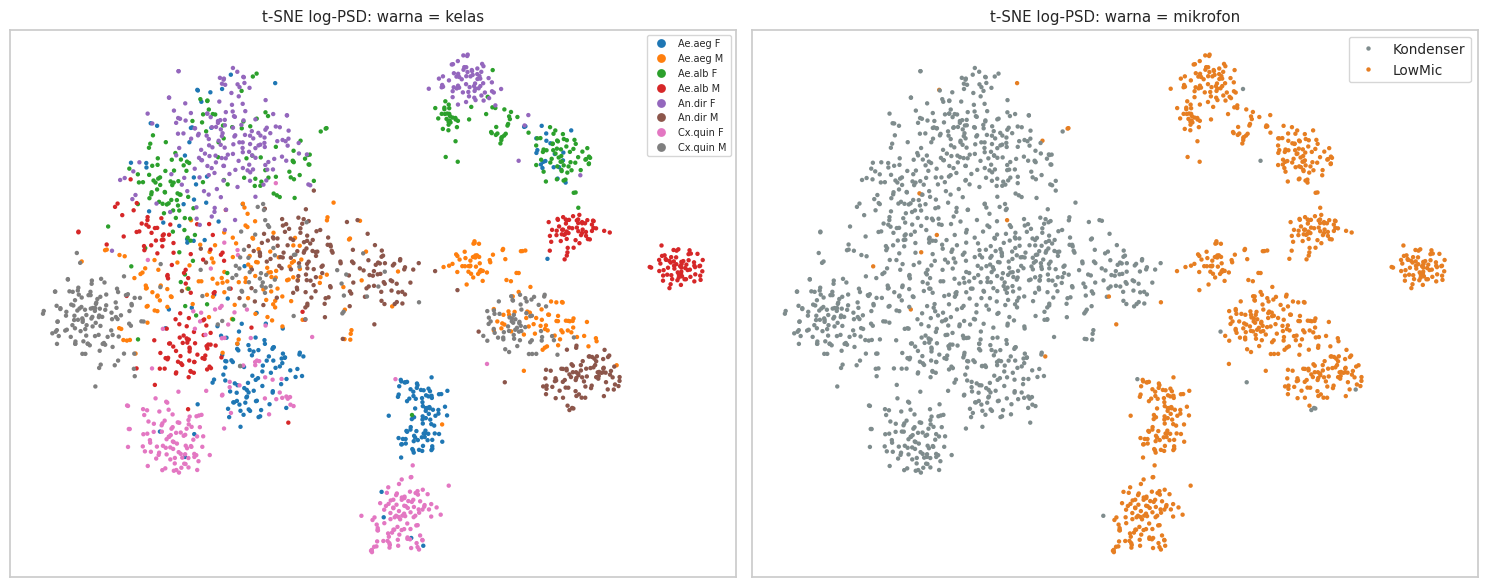

Indikasi keterpisahan (k-NN 5-fold acak, hanya ilustrasi): F0 saja 0.596 | log-PSD 64 pita 0.808


In [20]:
# 5.11 Proyeksi 2D (t-SNE) dari log-PSD 64 pita (100-4000 Hz), 250 epoch per kelas
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

edges = np.geomspace(100, 4000, 65)
bands = np.stack([PSD[:, (FREQ_PSD >= lo) & (FREQ_PSD < hi)].mean(1) if ((FREQ_PSD >= lo) & (FREQ_PSD < hi)).any()
                  else PSD[:, np.argmin(abs(FREQ_PSD - lo))] for lo, hi in zip(edges[:-1], edges[1:])], 1)
bands -= bands.mean(1, keepdims=True)                  # buang level absolut (setara augmentasi amplitudo)
sub = meta.groupby('kelas', group_keys=False).apply(lambda d: d.sample(min(250, len(d)), random_state=0)).idx.values
Z = TSNE(2, perplexity=40, init='pca', random_state=0).fit_transform(
    PCA(30, random_state=0).fit_transform(StandardScaler().fit_transform(bands[sub])))
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=meta.kelas.values[sub], hue_order=SHORT, palette=PAL, s=10, ax=ax[0], linewidth=0)
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=meta.mikrofon.values[sub], palette={'Kondenser': '#7f8c8d', 'LowMic': '#e67e22'},
                s=10, ax=ax[1], linewidth=0)
ax[0].set(title='t-SNE log-PSD: warna = kelas', xticks=[], yticks=[]); ax[0].legend(fontsize=7, markerscale=2)
ax[1].set(title='t-SNE log-PSD: warna = mikrofon', xticks=[], yticks=[])
plt.tight_layout(); plt.savefig('figures/eda_tsne.png', dpi=130); plt.show()

from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score
knn = cross_val_score(KNeighborsClassifier(15), StandardScaler().fit_transform(bands[sub]), meta.kelas.values[sub], cv=5).mean()
f0_only = cross_val_score(KNeighborsClassifier(15), meta.F0.values[sub, None], meta.kelas.values[sub], cv=5).mean()
print(f'Indikasi keterpisahan (k-NN 5-fold acak, hanya ilustrasi): F0 saja {f0_only:.3f} | log-PSD 64 pita {knn:.3f}')

In [21]:
# 5.12 Ringkasan angka kunci EDA
fem, mal = [c for c in SHORT if c.endswith('F')], [c for c in SHORT if c.endswith('M')]
med = meta.groupby('kelas').F0.median()
summary_eda = {
    'file rekaman': len(inv), 'durasi total (menit)': round(inv.durasi_s.sum() / 60, 1),
    'epoch 300 ms': len(meta), 'kelompok rekaman (unit split)': meta.kelompok.nunique(),
    'rasio ketidakseimbangan kelas': round(ep.total.max() / ep.total.min(), 2),
    'porsi epoch LowMic (%)': round(100 * (meta.mikrofon == 'LowMic').mean(), 1),
    'median F0 betina (Hz)': f'{med[fem].min():.0f}-{med[fem].max():.0f}',
    'median F0 jantan (Hz)': f'{med[mal].min():.0f}-{med[mal].max():.0f}',
    'pasangan F0 paling tumpang tindih': f'{pairs[0][1]} vs {pairs[0][2]} ({pairs[0][0]:.2f})',
    'k-NN F0 saja vs log-PSD': f'{f0_only:.3f} vs {knn:.3f}',
    'median SNR test G=1 (dB)': round(snr[snr.G == 1]['SNR (dB)'].median(), 1),
    'contoh test benar-benar ber-noise (%)': round(50 * np.mean(noisy_flag), 1),
    'epoch test dari file yang juga di train (%)': round(100 * tot.iloc[1] / tot.iloc[0], 1),
}
pd.Series(summary_eda, name='nilai').to_frame()

,nilai
file rekaman,1324
durasi total (menit),43.7
epoch 300 ms,15421
kelompok rekaman (unit split),28
rasio ketidakseimbangan kelas,3.37
porsi epoch LowMic (%),40.1
median F0 betina (Hz),457-581
median F0 jantan (Hz),339-990
pasangan F0 paling tumpang tindih,Ae.aeg M vs An.dir M (0.65)
k-NN F0 saja vs log-PSD,0.596 vs 0.808


### Temuan EDA dan implikasinya bagi pemodelan

Angka di bawah berasal dari run EDA pada data rilis (1.324 file, 43,7 menit, 15.421 epoch); sel 5.12 mencetak ulang angka kunci.

1. **Dua mikrofon merekam kejadian yang sama.** Lebih dari separuh file LowMic (303 dari 575) punya kembaran kondenser dengan nama dan durasi identik. Test hanya memakai LowMic, sedangkan train berisi keduanya. Split rilis memotong keduanya di titik kronologis yang sama sehingga potongan test kondenser dibuang, tetapi file kembar yang terpotong melintasi batas fold tetap bisa muncul di train. Karena itu analisis kebocoran (5.10) menghitung kebocoran **per file** dan **per file kembar**.
2. **Kelas tidak seimbang** (rasio 3,4: *Cx. quin* ♂ 21 % vs *An. dirus* ♂ 6 %). Train diseimbangkan dengan `RandomOverSampler`, dan metrik utama adalah **macro-F1**.
3. **Level RMS LowMic ±8-16 dB lebih tinggi** dari kondenser, tanpa clipping. Selisih ini terutama berasal dari komponen frekuensi rendah: di pita 250-2.000 Hz spektrum LowMic justru sedikit lebih lemah (5.6). Kedua mikrofon memotong spektrum di ±3,7 kHz. Augmentasi amplitudo ±12 dB menutup selisih level ini.
4. **Energi sinyal didominasi rumble < 60 Hz (70-86 %)**, sedangkan pita wingbeat 250-4.000 Hz hanya sekitar 4-7 %. Model raw waveform harus belajar mengabaikan komponen ini sendiri. MFCC (pita mel 100-4.000 Hz) dan spektrogram DenseNet121 (bin ≥ 100 Hz) membuangnya secara eksplisit, salah satu alasan fitur spektral berpotensi mengungguli MosquitoSong+.
5. **F0 betina sempit dan stabil** (median 457-581 Hz), **F0 jantan bimodal**: sebagian file didominasi nada ±270-450 Hz, sisanya ±700-1.000 Hz, dan proporsinya bergantung pada kelompok umur. Pasangan paling tumpang tindih: *Ae. aegypti* ♂ vs *An. dirus* ♂ dan *Ae. albopictus* ♀ vs *An. dirus* ♀. k-NN dengan F0 saja hanya ±0,60, sedangkan log-PSD 64 pita ±0,81: **bentuk spektrum jauh lebih informatif daripada F0**.
6. **Variasi antar kelompok umur besar** untuk jantan (selisih median F0 hingga > 500 Hz). Model harus menggeneralisasi lintas kelompok rekaman, bukan menghafal satu kelompok.
7. **Hanya 6 dari 12 file noise yang benar-benar mengganggu.** Enam file (grass cutter, broom, watering) punya dua kanal hampir identik (korelasi 1,00), sehingga `M2 − M1` meredamnya ±35-41 dB. Noise efektif berasal dari animals, grasscutting, motorcycle, dan suara perangkap CDC.
8. **Noise test tergolong ringan.** Median SNR 17,8 dB pada G = 1 (10 % terburuk < 2 dB), dan hanya 24 % contoh test akhir yang benar-benar ber-noise. Akurasi test sebagian besar mencerminkan kondisi bersih; karena itu notebook evaluasi memisahkan subset noisy dan clean.
9. **Simulasi 2 mikrofon hampir berupa penguatan rata** (±24-27 dB) di pita wingbeat. Efek utamanya ada pada noise, bukan pada bentuk spektrum wingbeat.
10. **Kebocoran 24,6 %** epoch test berasal dari file yang juga terpotong ke train di fold yang sama. Hasil akhir juga dilaporkan pada subset bebas-kebocoran.

## 6. Arsitektur Model

| Lapisan | MosquitoSong | MosquitoSong+ |
|---|---|---|
| 1 | conv 350, 32 filter, stride 4 | conv 100, 32 filter, stride 4 |
| 2 | max-pool 4, stride 4 | conv 64, 32 filter, stride 4 |
| 3 | conv 100, 32 filter, stride 1 | conv 64, 64 filter, stride 3 |
| 4 | max-pool 3, stride 3 | max-pool 3, stride 3 |
| Kepala | dropout 0,5 → FC 256 → FC 128 → softmax 8 | sama |

Perubahan utama MosquitoSong+ adalah mengganti down-sampling statistik (max-pool) dengan konvolusi ber-stride yang bobotnya dipelajari. Padding tidak disebut di paper, jadi dipakai `valid`.

In [22]:
# [lib] model-mosquitosong
def mosquitosong(n_classes=8, input_len=2400):
    """MosquitoSong (Fig. 2 kiri): down-sampling dengan max-pool."""
    inp = L.Input((input_len, 1))
    x = L.Conv1D(32, 350, strides=4, activation='relu')(inp)
    x = L.MaxPooling1D(4, strides=4)(x)
    x = L.Conv1D(32, 100, strides=1, activation='relu')(x)
    x = L.MaxPooling1D(3, strides=3)(x)
    x = L.Dropout(0.5)(x)
    x = L.Flatten()(x)
    x = L.Dense(256, activation='relu')(x)
    x = L.Dense(128, activation='relu')(x)
    out = L.Dense(n_classes, activation='softmax', dtype='float32')(x)
    return keras.Model(inp, out, name='MosquitoSong')


def mosquitosong_plus(n_classes=8, input_len=2400):
    """MosquitoSong+ (Fig. 2 kanan): tiga conv bertingkat sebagai down-sampling yang dipelajari."""
    inp = L.Input((input_len, 1))
    x = L.Conv1D(32, 100, strides=4, activation='relu')(inp)
    x = L.Conv1D(32, 64, strides=4, activation='relu')(x)
    x = L.Conv1D(64, 64, strides=3, activation='relu')(x)
    x = L.MaxPooling1D(3, strides=3)(x)
    x = L.Dropout(0.5)(x)
    x = L.Flatten()(x)
    x = L.Dense(256, activation='relu')(x)
    x = L.Dense(128, activation='relu')(x)
    out = L.Dense(n_classes, activation='softmax', dtype='float32')(x)
    return keras.Model(inp, out, name='MosquitoSongPlus')


MODELS = {'mosquitosong': mosquitosong, 'mosquitosong_plus': mosquitosong_plus}

In [23]:
for name, build in MODELS.items():
    m = build()
    print(f'{m.name}: {m.count_params():,} parameter')
    m.summary(line_length=90)

MosquitoSong: 221,576 parameter


Model: "MosquitoSong"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                          ┃ Output Shape                 ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)              │ (None, 2400, 1)              │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ conv1d (Conv1D)                       │ (None, 513, 32)              │          11,232 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ max_pooling1d (MaxPooling1D)          │ (None, 128, 32)              │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ conv1d_1 (Conv1D)                     │ (None, 29, 32)               │         102,432 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ max_pooling1d_1 (MaxPooling1D)        │ (None, 9, 32)                │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ dropout (Dropout)                     │ (None, 9, 32)                │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ flatten (Flatten)                     │ (None, 288)                  │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ dense (Dense)                         │ (None, 256)                  │          73,984 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                       │ (None, 128)                  │          32,896 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                       │ (None, 8)                    │           1,032 │
└───────────────────────────────────────┴──────────────────────────────┴─────────────────┘

 Total params: 221,576 (865.53 KB)

 Trainable params: 221,576 (865.53 KB)

 Non-trainable params: 0 (0.00 B)

... (2 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                          ┃ Output Shape                 ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)            │ (None, 2400, 1)              │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ conv1d_2 (Conv1D)                     │ (None, 576, 32)              │           3,232 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ conv1d_3 (Conv1D)                     │ (None, 129, 32)              │          65,568 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ conv1d_4 (Conv1D)                     │ (None, 22, 64)               │         131,136 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ max_pooling1d_2 (MaxPooling1D)        │ (None, 7, 64)                │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                   │ (None, 7, 64)                │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                   │ (None, 448)                  │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                       │ (None, 256)                  │         114,944 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                       │ (None, 128)                  │          32,896 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                       │ (None, 8)                    │           1,032 │
└───────────────────────────────────────┴──────────────────────────────┴─────────────────┘

 Total params: 348,808 (1.33 MB)

 Trainable params: 348,808 (1.33 MB)

 Non-trainable params: 0 (0.00 B)

## 7. Augmentasi dan Training

Augmentasi dibuat **baru di setiap epoch** untuk setiap contoh training:

| Augmentasi | Nilai | MosquitoSong | MosquitoSong+ |
|---|---|---|---|
| Time shift (sirkular) | ±10 % dari 300 ms | ✓ | ✓ |
| Volume wingbeat G | U(1, 2) | G = 1 | ✓ |
| Simulasi 2-mic + cancellation | geometri kode rilis | ✓ | ✓ |
| Noise lingkungan N-OUTDOOR | p = 0,9, file & offset acak | – | ✓ |
| Amplitudo | ×¼ sampai ×4 (-12 sampai 12 dB) | ✓ | ✓ |
| Gaussian noise | faktor U(0,001, 0,01) | ✓ | ✓ |

Kelas diseimbangkan dengan `RandomOverSampler` (seperti notebook rilis), sehingga *weighted cross-entropy* dari paper menjadi cross-entropy biasa. Model terbaik dipilih dari **val loss minimum**. Setelah training, `preds.npz` menyimpan probabilitas test (noisy/clean × G) dan probabilitas validation, yang dipakai notebook 03 untuk ensemble.

In [24]:
# [lib] augmentasi
def augment_batch(X, rng, noise=None, noise_aug=True, p_noise=0.9, gain_range=(1.0, 2.0)):
    """Augmentasi baru untuk setiap contoh di setiap epoch (vektorisasi numpy):
    1) time shift sirkular ±10 %; 2) volume G~U(1,2) [noise_aug]; 3) simulasi 2-mic + cancellation;
    4) noise N-OUTDOOR p=0.9 [noise_aug]; 5) amplitudo -12..12 dB; 6) Gaussian U(0.001,0.01)."""
    n = len(X)
    shifts = rng.integers(-TARGET // 10, TARGET // 10 + 1, size=n)
    idx = (np.arange(TARGET)[None, :] - shifts[:, None]) % TARGET
    x = np.take_along_axis(X, idx, axis=1)

    g = rng.uniform(*gain_range, size=(n, 1)).astype(np.float32) if noise_aug else np.ones((n, 1), np.float32)
    x = mosquito_cancelled(x, g)

    if noise_aug and noise:
        add = rng.random(n) < p_noise
        files = rng.integers(0, len(noise), size=n)
        for i in np.where(add)[0]:
            n1, n2 = noise[files[i]]
            s = rng.integers(0, len(n1) - TARGET + 1)
            x[i] += n2[s:s + TARGET] - n1[s:s + TARGET]

    x *= (10 ** (rng.uniform(-12, 12, size=(n, 1)) / 20)).astype(np.float32)
    x += rng.uniform(0.001, 0.01, size=(n, 1)).astype(np.float32) * rng.standard_normal(x.shape).astype(np.float32)
    return x.astype(np.float32)

In [25]:
# [lib] training-per-fold
DEFAULT_CFG = dict(model='mosquitosong_plus', fold=0, epochs=1000, batch=64, lr=1e-4, seed=42,
                   recipe='paper', patience=0, tag='', precision='fp32', no_noise_aug=False, pretrained=True,
                   data='data', out='runs', log_every=10, ckpt_every=10, deadline=None, pause_at=0, max_train=0)
PRED_BATCH = 256          # batch inferensi (cukup kecil untuk DenseNet121 128x128 di T4)
PRETRAINED_MODELS = set() # model yang menerima argumen pretrained=... (diisi sel DenseNet121)


def oversample(X, y, random_state=42):
    """RandomOverSampler(sampling_strategy='all', random_state=42) seperti notebook rilis;
    fallback numpy setara bila imbalanced-learn tidak terpasang."""
    try:
        from imblearn.over_sampling import RandomOverSampler
        return RandomOverSampler(sampling_strategy='all', random_state=random_state).fit_resample(X, y)
    except ImportError:
        rng = np.random.default_rng(random_state)
        n_max = np.bincount(y).max()
        idx = np.concatenate([np.concatenate([np.where(y == c)[0], rng.choice(np.where(y == c)[0], n_max - (y == c).sum())])
                              for c in np.unique(y)])
        return X[idx], y[idx]


def setup_device(precision):
    for gpu in tf.config.list_physical_devices('GPU'):
        try:
            tf.config.experimental.set_memory_growth(gpu, True)
        except RuntimeError:
            pass                                    # GPU sudah diinisialisasi (fold kedua in-process)
    keras.mixed_precision.set_global_policy({'bf16': 'mixed_bfloat16', 'fp16': 'mixed_float16'}.get(precision, 'float32'))
    gpus = tf.config.list_physical_devices('GPU')
    return 'GPU:' + ','.join(tf.config.experimental.get_device_details(g).get('device_name', '?') for g in gpus) \
        if gpus else 'CPU:' + (platform.processor() or platform.machine())


def build_model(name, pretrained=True):
    fn = MODELS[name]
    return fn(len(CLASSES), pretrained=pretrained) if name in PRETRAINED_MODELS else fn(len(CLASSES))


def save_checkpoint(ckpt_dir, model, rng, state):
    """Checkpoint tengah-fold: bobot terakhir + state optimizer + state RNG augmentasi + histori.
    Semua file ditulis lewat nama sementara lalu diganti; state.json ditulis terakhir (penanda checkpoint valid)."""
    os.makedirs(ckpt_dir, exist_ok=True)
    model.save_weights(os.path.join(ckpt_dir, 'last.tmp.weights.h5'))
    os.replace(os.path.join(ckpt_dir, 'last.tmp.weights.h5'), os.path.join(ckpt_dir, 'last.weights.h5'))
    opt = {f'v{i}': keras.ops.convert_to_numpy(v) for i, v in enumerate(model.optimizer.variables)}
    np.savez(os.path.join(ckpt_dir, 'optimizer.tmp.npz'), **opt)
    os.replace(os.path.join(ckpt_dir, 'optimizer.tmp.npz'), os.path.join(ckpt_dir, 'optimizer.npz'))
    with open(os.path.join(ckpt_dir, 'state.tmp.json'), 'w') as f:
        json.dump({**state, 'rng': rng.bit_generator.state}, f, default=str)
    os.replace(os.path.join(ckpt_dir, 'state.tmp.json'), os.path.join(ckpt_dir, 'state.json'))


def load_checkpoint(ckpt_dir, model, rng):
    with open(os.path.join(ckpt_dir, 'state.json')) as f:
        state = json.load(f)
    model.optimizer.build(model.trainable_variables)   # bangun optimizer dulu agar bobotnya bisa diisi
    model.load_weights(os.path.join(ckpt_dir, 'last.weights.h5'))
    saved = np.load(os.path.join(ckpt_dir, 'optimizer.npz'))
    if len(saved.files) == len(model.optimizer.variables):
        for i, v in enumerate(model.optimizer.variables):
            v.assign(saved[f'v{i}'])
    elif state['epoch'] > 0:                           # jeda di epoch 0: belum ada state optimizer
        print('Peringatan: state optimizer tidak cocok, optimizer dimulai ulang', flush=True)
    rng.bit_generator.state = state.pop('rng')
    return state


def run_fold(cfg):
    """Latih + evaluasi satu (model, fold). Artefak: runs/<nama>/fold<k>/
    best.weights.h5, history.csv, preds.npz (probabilitas test + validation), config.json (penanda fold lengkap).
    Selama training, ckpt/ diperbarui tiap `ckpt_every` epoch. Fold dijeda (checkpoint disimpan) bila
    `deadline` (waktu absolut) terlewati atau epoch mencapai `pause_at` (pilot); sesi berikutnya melanjutkan."""
    a = SimpleNamespace(**{**DEFAULT_CFG, **cfg})
    run_name = a.model + (f'_{a.tag}' if a.tag else '')
    out_dir = os.path.join(a.out, run_name, f'fold{a.fold}')
    ckpt_dir = os.path.join(out_dir, 'ckpt')
    os.makedirs(out_dir, exist_ok=True)
    seed = a.seed + a.fold
    keras.utils.set_random_seed(seed)
    device = setup_device(a.precision)
    rng = np.random.default_rng(seed)

    epochs_ = load_epochs(os.path.join(a.data, 'mosquito_recordings'))
    noise, noise_names = load_noise(os.path.join(a.data, 'environmental_noise_recordings'))
    s = split_fold(epochs_, count_per_group(epochs_), a.fold)
    Xtr, ytr = oversample(s['train'][0], encode(s['train'][1]))
    Xva, yva = s['val'][0], encode(s['val'][1])
    Xte, yte = s['test'][0], encode(s['test'][1])
    if a.max_train:                                     # hanya untuk uji cepat lokal
        sub = np.random.default_rng(0).choice(len(ytr), min(a.max_train, len(ytr)), replace=False)
        Xtr, ytr = Xtr[sub], ytr[sub]

    va = make_noisy_set(Xva, 2500, noise)               # validation: noise overlay G=1,1.5,2 (seed 2500)
    Xva_all, yva_all = np.concatenate([va[g] for g in GAINS])[..., None], np.tile(yva, len(GAINS))

    noise_aug = a.model != 'mosquitosong' and not a.no_noise_aug   # MosquitoSong lama: tanpa noise aug
    model = build_model(a.model, a.pretrained)
    steps = int(np.ceil(len(ytr) / a.batch)) * a.epochs
    lr = keras.optimizers.schedules.CosineDecay(a.lr, steps, alpha=0.01) if a.recipe in ('fast', 'finetune') else a.lr
    model.compile(optimizer=keras.optimizers.Adam(lr), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

    hist, best, best_ep, start_ep, elapsed0 = [], np.inf, -1, 0, 0.0
    weights_path = os.path.join(out_dir, 'best.weights.h5')
    if os.path.exists(os.path.join(ckpt_dir, 'state.json')):          # lanjutkan fold yang terjeda
        st = load_checkpoint(ckpt_dir, model, rng)
        hist, best, best_ep, start_ep, elapsed0 = st['hist'], st['best'], st['best_ep'], st['epoch'], st['elapsed']
        print(f'[{run_name} f{a.fold}] resume dari checkpoint: epoch {start_ep}, best@{best_ep}', flush=True)
    t0 = time.time() - elapsed0

    def state(epoch_done):
        return dict(epoch=epoch_done, hist=hist, best=best, best_ep=best_ep, elapsed=time.time() - t0)

    def pause(ep, why):
        save_checkpoint(ckpt_dir, model, rng, state(ep))
        print(f'[{run_name} f{a.fold}] dijeda di epoch {ep} ({why}); dilanjutkan dari checkpoint', flush=True)
        return {'status': 'paused', 'epoch': ep}

    print(f'[{run_name} f{a.fold}] device={device} lr={a.lr:g} train={len(ytr)} val={len(yva_all)} test={len(yte)} '
          f'params={model.count_params():,}', flush=True)
    for ep in range(start_ep, a.epochs):
        if a.pause_at and ep >= a.pause_at:
            return pause(ep, f'pilot {a.pause_at} epoch')
        if a.deadline and time.time() > a.deadline:
            return pause(ep, 'batas waktu sesi')
        Xa = augment_batch(Xtr, rng, noise, noise_aug=noise_aug)[..., None]
        h = model.fit(Xa, ytr, batch_size=a.batch, epochs=1, shuffle=True, verbose=0)
        vl, vacc = model.evaluate(Xva_all, yva_all, batch_size=PRED_BATCH, verbose=0)
        hist.append(dict(epoch=ep + 1, loss=h.history['loss'][0], acc=h.history['accuracy'][0],
                         val_loss=vl, val_acc=vacc, t=time.time() - t0))
        if vl < best:                                   # pemilihan model: val loss minimum
            best, best_ep = vl, ep + 1
            model.save_weights(weights_path)
        if (ep + 1) % a.log_every == 0 or ep == start_ep:
            print(f'[{run_name} f{a.fold}] ep {ep+1}/{a.epochs} loss {h.history["loss"][0]:.4f} '
                  f'val_loss {vl:.4f} val_acc {vacc:.4f} best@{best_ep} ({time.time()-t0:.0f}s)', flush=True)
        if a.patience and ep + 1 - best_ep >= a.patience:
            print(f'[{run_name} f{a.fold}] early stop at epoch {ep+1}', flush=True)
            break
        if a.ckpt_every and (ep + 1) % a.ckpt_every == 0:
            save_checkpoint(ckpt_dir, model, rng, state(ep + 1))
    pd.DataFrame(hist).to_csv(os.path.join(out_dir, 'history.csv'), index=False)

    model.load_weights(weights_path)                    # test: protokol rilis (noisy + clean, tiap G)
    te_noisy, te_clean = make_noisy_set(Xte, 0, noise), make_clean_set(Xte)
    preds = {'y': yte, 'y_val': yva_all, 'val': model.predict(Xva_all, batch_size=PRED_BATCH, verbose=0)}
    for g in GAINS:
        preds[f'noisy_G{g}'] = model.predict(te_noisy[g][..., None], batch_size=PRED_BATCH, verbose=0)
        preds[f'clean_G{g}'] = model.predict(te_clean[g][..., None], batch_size=PRED_BATCH, verbose=0)
    np.savez_compressed(os.path.join(out_dir, 'preds.npz'), **preds)
    acc = float(np.mean([(preds[f'{c}_G{g}'].argmax(1) == yte).mean() for c in ('noisy', 'clean') for g in GAINS]))

    meta = dict(vars(a), run=run_name, seed_effective=seed, best_epoch=best_ep, best_val_loss=best,
                epochs_run=len(hist), resumed_from_epoch=start_ep, n_train_balanced=len(ytr), n_val=len(yva),
                n_test=len(yte), noise_aug=noise_aug, noise_files=noise_names, classes=CLASSES, device=device,
                params=model.count_params(), tf=tf.__version__, keras=keras.__version__, numpy=np.__version__,
                python=platform.python_version(), train_time_s=time.time() - t0, test_acc_all=acc)
    with open(os.path.join(out_dir, 'config.json'), 'w') as f:      # ditulis terakhir = penanda fold lengkap
        json.dump(meta, f, indent=2, default=str)
    shutil.rmtree(ckpt_dir, ignore_errors=True)        # checkpoint tidak diperlukan lagi
    print(f'[{run_name} f{a.fold}] done. best epoch {best_ep}, test ACC {acc:.3f}, '
          f'{(time.time()-t0)/60:.1f} min', flush=True)
    return {'status': 'done', **meta}

### Rancangan Eksperimen

```text
Rekaman WAV (W-INDOOR, 8 kHz)
    |
    v
Segmentasi 300 ms, hop 150 ms (+ jitter 0-119 sampel)
    |
    v
Split 10-fold kronologis per kelompok rekaman
    |
    +--> TRAIN: RandomOverSampler --> augmentasi baru tiap epoch
    |       MosquitoSong : shift, amplitudo, Gaussian, 2-mic (G = 1)
    |       MosquitoSong+: + noise N-OUTDOOR (p = 0,9) + volume G ~ U(1, 2)
    |
    +--> VALIDATION: noise overlay G = 1; 1,5; 2 (seed 2500) --> pilih epoch dengan val loss minimum
    |
    +--> TEST (LowMic, kuota per kelompok): noisy + clean × G = 1; 1,5; 2
                         |
                         v
     Prediksi per fold --> metrik gabungan (Tabel 3 & 4) --> uji signifikansi
```

### Tabel Konfigurasi

| Item | Paper | Notebook ini |
|---|---|---|
| Input | 300 ms @ 8 kHz, hop 150 ms | sama |
| Optimizer | Adam, lr 1e-4 | sama |
| Epoch | 1000, model terbaik di validation | 1000, val loss minimum |
| Batch size | tidak disebut | 64 |
| Loss | weighted cross-entropy | cross-entropy + RandomOverSampler |
| Seed | tidak disebut | 42 + nomor fold |

### Kriteria Evaluasi

- **Metrik utama:** akurasi (ACC) dan macro-F1 (MF1) dari prediksi gabungan 10 fold × 3 nilai G, sama dengan cara paper menghitung Tabel 3.
- **Per kelas:** precision, recall, F1 untuk tiap G (Tabel 4).
- **Confusion matrix:** satu fold (seperti Fig. 3 paper) dan gabungan semua fold.
- **Uji statistik (H1):** Mann-Whitney U satu sisi (seperti paper), paired t-test, dan *corrected resampled t-test* (Nadeau & Bengio) pada MF1 per fold.

## 8. Menjalankan Training 10 Fold

Setiap fold dijalankan sebagai proses terpisah (satu per GPU): dengan dua GPU dua fold dilatih paralel, dengan satu GPU berurutan. Log tiap fold ada di `logs/`. Perkiraan di T4: ±90 menit per fold untuk MosquitoSong+ dan ±80 menit untuk MosquitoSong.

**Checkpoint:** setiap 10 epoch, `runs/<model>/fold<k>/ckpt/` menyimpan bobot terakhir, state optimizer, state RNG augmentasi, dan histori. Menjelang `TIME_BUDGET_H`, fold yang sedang berjalan disimpan lalu dijeda, sehingga sesi Kaggle selesai dengan rapi dan output tersimpan. Pada sesi berikutnya (output versi ini ditambahkan sebagai Input), fold itu dilanjutkan dari epoch terakhir; paling banyak 10 epoch yang diulang.

In [26]:
def plan_jobs():
    """Semua (eksperimen, fold) yang belum lengkap; fold terjeda didahulukan."""
    return paused_first([(x, f, 0) for f in FOLD_ROUNDS for x in RUN if not fold_done(x, f)])

In [27]:
def run_name(exp):
    e = EXPERIMENTS[exp]
    return e['model'] + (f"_{e['tag']}" if e.get('tag') else '')


def fold_dir(exp, fold):
    return f'runs/{run_name(exp)}/fold{fold}'


def fold_done(exp, fold):
    """Fold dianggap lengkap bila preds.npz dan config.json (ditulis terakhir) ada."""
    return os.path.exists(f'{fold_dir(exp, fold)}/preds.npz') and os.path.exists(f'{fold_dir(exp, fold)}/config.json')


def ckpt_epoch(exp, fold):
    """Epoch checkpoint tengah-fold (-1 bila tidak ada)."""
    try:
        return json.load(open(f'{fold_dir(exp, fold)}/ckpt/state.json'))['epoch']
    except (OSError, ValueError, KeyError):
        return -1


def fold_paused(exp, fold):
    return not fold_done(exp, fold) and ckpt_epoch(exp, fold) >= 0


META_KEYS = {'family', 'lr_from', 'seed_of'}          # kunci penjadwalan, bukan argumen training


def job_cfg(job, deadline=None):
    """job = (eksperimen, fold, pause_at). lr untuk eksperimen 'lr_from' dipilih per fold dari val loss fold itu."""
    exp, fold, pause_at = job
    e = {k: v for k, v in EXPERIMENTS[exp].items() if k not in META_KEYS}
    if EXPERIMENTS[exp].get('lr_from'):
        e['lr'] = EXPERIMENTS[selected_exp(EXPERIMENTS[exp]['lr_from'], fold)]['lr']
    paper = e['recipe'] == 'paper'
    return {'precision': PRECISION, 'seed': SEED, **e, 'fold': fold, 'data': 'data', 'out': 'runs',
            'log_every': 50 if paper else 5, 'ckpt_every': 10 if paper else 5,
            'deadline': deadline, 'pause_at': pause_at, 'max_train': MAX_TRAIN}


def family_exps(family):
    """Varian lr dari satu keluarga model (bukan ablation/seed)."""
    return [x for x, e in EXPERIMENTS.items() if e.get('family') == family]


def selected_exp(family, fold):
    """Varian lr dengan val loss minimum di fold itu sendiri; None bila belum semua varian selesai."""
    cands = family_exps(family)
    if not cands or not all(fold_done(x, fold) for x in cands):
        return None
    return min(cands, key=lambda x: json.load(open(f'{fold_dir(x, fold)}/config.json'))['best_val_loss'])


def paused_first(jobs):
    return sorted(jobs, key=lambda j: not fold_paused(j[0], j[1]))   # sort stabil: urutan lain tetap


def export_library(path='mosq_lib.py'):
    """Gabungkan sel '# [lib] ...' (versi terakhir yang dieksekusi) menjadi satu modul
    agar setiap fold bisa dijalankan sebagai proses terpisah, satu proses per GPU."""
    history = globals().get('In') or []
    cells = {}
    for src in history:
        first = src.lstrip().split('\n', 1)[0]
        if first.startswith('# [lib]'):
            cells[first] = src
    if not cells:
        raise RuntimeError('Sel [lib] tidak ditemukan di riwayat eksekusi; jalankan notebook dari atas.')
    with open(path, 'w') as f:
        f.write('\n\n'.join(cells.values()))
        f.write("\n\n\nif __name__ == '__main__':\n    run_fold(json.loads(sys.argv[1]))\n")
    return path, list(cells)


def gpu_slots():
    import subprocess
    if os.environ.get('FORCE_WORKERS'):                # uji lokal jalur paralel di CPU
        return [''] * int(os.environ['FORCE_WORKERS'])
    try:
        out = subprocess.run(['nvidia-smi', '-L'], capture_output=True, text=True).stdout
        return [str(i) for i, l in enumerate(out.splitlines()) if l.startswith('GPU')]
    except FileNotFoundError:
        return []


def run_queue():
    """Jalankan job dari plan_jobs() sampai habis atau mendekati TIME_BUDGET_H.
    plan_jobs() dievaluasi ulang setiap ada slot kosong, jadi tahap berikutnya (mis. setelah gerbang pilot)
    langsung berjalan di sesi yang sama. Fold terjeda dilanjutkan dari checkpoint."""
    import subprocess
    os.makedirs('logs', exist_ok=True)
    t0 = time.time()
    deadline = t0 + TIME_BUDGET_H * 3600
    slots, outcome, failed = gpu_slots(), {'selesai': [], 'dijeda': [], 'gagal': []}, set()
    print(f'{len(plan_jobs())} job siap dijalankan sekarang | slot GPU: {slots or "tidak ada (CPU)"}')

    def log_path(job):
        return f'logs/{run_name(job[0])}_fold{job[1]}.log'

    def next_job(busy):
        if deadline - time.time() < 300:                 # jangan mulai job baru bila sisa < 5 menit
            return None
        return next((j for j in plan_jobs() if j[:2] not in busy and j[:2] not in failed), None)

    def record(job):
        key = 'selesai' if fold_done(*job[:2]) else 'dijeda' if fold_paused(*job[:2]) else 'gagal'
        if key == 'gagal':
            failed.add(job[:2])
        outcome[key].append(f'{run_name(job[0])}/fold{job[1]}')
        return key

    def stamp():
        return f'[{(time.time()-t0)/3600:5.2f} h]'

    slots = slots or ['']                                # tanpa GPU: satu slot CPU
    # satu proses per GPU (atau satu proses CPU): memori dibebaskan setiap job selesai
    lib, names = export_library()
    print(f'{lib}: {len(names)} sel [lib] digabung')
    running = {}                                     # indeks slot -> (proses, job, log)
    try:
        while True:
            for i, (p, job, log) in list(running.items()):
                if p.poll() is not None:
                    del running[i]; log.close()
                    tail = open(log_path(job)).read().strip().splitlines()[-1:]
                    print(f'{stamp()} {record(job):8s} {run_name(job[0])} fold {job[1]} rc={p.returncode} → '
                          f'{tail[0] if tail else ""}', flush=True)
            for i in range(len(slots)):
                if i in running:
                    continue
                job = next_job({j[:2] for _, j, _ in running.values()})
                if job is None:
                    break
                env = dict(os.environ, CUDA_VISIBLE_DEVICES=slots[i], TF_CPP_MIN_LOG_LEVEL='2')
                log = open(log_path(job), 'a')
                resumed = fold_paused(*job[:2])
                p = subprocess.Popen([sys.executable, lib, json.dumps(job_cfg(job, deadline))],
                                     cwd=WORK, env=env, stdout=log, stderr=subprocess.STDOUT)
                running[i] = (p, job, log)
                print(f'{stamp()} mulai    {run_name(job[0])} fold {job[1]} di GPU {slots[i] or "CPU"}'
                      f'{" (lanjut dari checkpoint)" if resumed else ""}', flush=True)
            if not running:
                break
            time.sleep(1 if SMOKE else 20)
    except KeyboardInterrupt:
        for p, *_ in running.values():
            p.terminate()
        print('Dihentikan manual; fold terjeda dilanjutkan dari checkpoint terakhir (maks. 10 epoch hilang).')
    print({k: len(v) for k, v in outcome.items()})
    if outcome['gagal']:
        print('Gagal (lihat logs/):', outcome['gagal'])
    left = plan_jobs()
    note = globals().get('PLAN_NOTE')                   # alasan tidak ada job (mis. menunggu acuan gerbang pilot)
    print(note if not left and note else 'Semua job selesai.' if not left else
          f'Masih ada {len(left)} job: tambahkan output versi ini sebagai Input lalu jalankan ulang (resume).')


run_queue()

20 job siap dijalankan sekarang | slot GPU: ['0', '1']
mosq_lib.py: 7 sel [lib] digabung
[ 0.00 h] mulai    mosquitosong_plus fold 0 di GPU 0
[ 0.00 h] mulai    mosquitosong fold 0 di GPU 1
[ 1.34 h] selesai  mosquitosong fold 0 rc=0 → [mosquitosong f0] done. best epoch 33, test ACC 0.863, 80.4 min
[ 1.34 h] mulai    mosquitosong_plus fold 1 di GPU 1
[ 1.51 h] selesai  mosquitosong_plus fold 0 rc=0 → [mosquitosong_plus f0] done. best epoch 71, test ACC 0.897, 90.4 min
[ 1.51 h] mulai    mosquitosong fold 1 di GPU 0
[ 2.86 h] selesai  mosquitosong fold 1 rc=0 → [mosquitosong f1] done. best epoch 258, test ACC 0.910, 80.3 min
[ 2.86 h] mulai    mosquitosong_plus fold 2 di GPU 0
[ 2.86 h] selesai  mosquitosong_plus fold 1 rc=0 → [mosquitosong_plus f1] done. best epoch 505, test ACC 0.946, 90.5 min
[ 2.86 h] mulai    mosquitosong fold 2 di GPU 1
[ 4.20 h] selesai  mosquitosong fold 2 rc=0 → [mosquitosong f2] done. best epoch 70, test ACC 0.913, 79.9 min
[ 4.20 h] mulai    mosquitosong_plus

In [28]:
# Status kelengkapan 10 fold per eksperimen (✓ lengkap, ◐n terjeda di epoch n, – belum)
def fold_symbol(x, f):
    if fold_done(x, f):
        return '✓'
    return f'◐{ckpt_epoch(x, f)}' if ckpt_epoch(x, f) >= 0 else '–'


status = pd.DataFrame({f'fold {f}': [fold_symbol(x, f) for x in EXPERIMENTS] for f in range(10)},
                      index=[run_name(x) for x in EXPERIMENTS])
status['lengkap'] = [f"{sum(fold_done(x, f) for f in range(10))}/10" for x in EXPERIMENTS]
status

,fold 0,fold 1,fold 2,fold 3,fold 4,fold 5,fold 6,fold 7,fold 8,fold 9,lengkap
mosquitosong_plus,✓,✓,✓,✓,✓,✓,✓,◐817,–,–,7/10
mosquitosong,✓,✓,✓,✓,✓,✓,✓,◐878,–,–,7/10


## 9. Evaluasi Checkpoint Rilis Penulis

Checkpoint `cnn_model_min_val_round1..10.h5` dari repo dievaluasi dengan split dan test set yang sama. Hasilnya menjadi acuan independen: bila checkpoint rilis juga memberi angka di atas paper pada protokol ini, selisih replikasi kita berasal dari protokol evaluasi, bukan dari cara training. Checkpoint ini berarsitektur **MosquitoSong** (221.576 parameter), bukan MosquitoSong+.

In [29]:
# Evaluasi checkpoint rilis penulis (models/cnn_model_min_val_round{1..10}.h5), tanpa training
import h5py


def load_released(path):
    """Checkpoint rilis disimpan dengan TF 2.4 (format h5 lama). Coba keras.models.load_model; bila gagal,
    salin bobot per layer ke arsitektur MosquitoSong dari bagian 6 (urutan layer berbobot dan bentuknya harus cocok)."""
    try:
        m = keras.models.load_model(path, compile=False)
        print(f'  load_model OK: {m.count_params():,} parameter')
        return m
    except Exception as err:
        print(f'  load_model gagal ({type(err).__name__}); memakai salin-bobot per layer')
    m = mosquitosong()
    with h5py.File(path, 'r') as f:
        g = f['model_weights'] if 'model_weights' in f else f
        dec = lambda v: v.decode() if isinstance(v, bytes) else v
        arrays = []
        for name in map(dec, g.attrs['layer_names']):
            wnames = [dec(w) for w in g[name].attrs['weight_names']]
            if wnames:
                arrays.append([np.array(g[name][w]) for w in wnames])
    layers = [l for l in m.layers if l.weights]
    assert len(layers) == len(arrays), f'{len(layers)} layer berbobot vs {len(arrays)} di file'
    for layer, ws in zip(layers, arrays):
        layer.set_weights(ws)
    return m


ckpts = {int(re.search(r'round(\d+)', p).group(1)): p
         for p in glob.glob(os.path.join(INPUT, '**', 'cnn_model_min_val_round*.h5'), recursive=True)}
if not ckpts:
    print('Checkpoint rilis tidak ditemukan di Input. Unggah folder models/ (cnn_model_min_val_round1..10.h5) '
          'sebagai Kaggle Dataset lalu Add Input untuk menjalankan bagian ini.')
for rnd, path in sorted(ckpts.items()):
    k = rnd - 1                                         # round 1..10 di notebook rilis = fold 0..9
    out_dir = f'runs/released_mosquitosong/fold{k}'
    if os.path.exists(f'{out_dir}/config.json'):
        continue
    print(f'round {rnd} -> fold {k}: {os.path.basename(path)}')
    m = load_released(path)
    s = split_fold(E, totals, k)
    Xte, yte = s['test'][0], encode(s['test'][1])
    te_noisy, te_clean = make_noisy_set(Xte, 0, noise), make_clean_set(Xte)
    preds = {'y': yte}
    for g in GAINS:
        preds[f'noisy_G{g}'] = m.predict(te_noisy[g][..., None], batch_size=256, verbose=0)
        preds[f'clean_G{g}'] = m.predict(te_clean[g][..., None], batch_size=256, verbose=0)
    os.makedirs(out_dir, exist_ok=True)
    np.savez_compressed(f'{out_dir}/preds.npz', **preds)
    acc = float(np.mean([(preds[c].argmax(1) == yte).mean() for c in preds if c != 'y']))
    json.dump({'model': 'mosquitosong', 'run': 'released_mosquitosong', 'fold': k, 'source': path,
               'params': m.count_params(), 'test_acc_all': acc, 'best_val_loss': None, 'train_time_s': 0},
              open(f'{out_dir}/config.json', 'w'), indent=2)
    print(f'  fold {k}: test ACC {acc:.3f}')
    keras.backend.clear_session()

Checkpoint rilis tidak ditemukan di Input. Unggah folder models/ (cnn_model_min_val_round1..10.h5) sebagai Kaggle Dataset lalu Add Input untuk menjalankan bagian ini.


## 10. Hasil vs Paper

Metrik dihitung dari prediksi gabungan semua fold yang sudah selesai. Bila belum lengkap 10 fold, jumlah fold ditampilkan di tabel dan angkanya bersifat sementara.

In [30]:
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_recall_fscore_support
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

RUN_LABELS = {'mosquitosong_plus': 'MosquitoSong+', 'mosquitosong': 'MosquitoSong',
              'released_mosquitosong': 'Checkpoint rilis (MosquitoSong)',
              'mfcc_cnn': 'MFCC-CNN', 'ecapa_mfcc': 'ECAPA-MFCC', 'densenet121': 'DenseNet121-spektrogram',
              'mosquitosong_plus_mfcc': 'MosquitoSong+ + MFCC', 'densenet121_asp': 'DenseNet121-ASP',
              'ensemble': 'Ensemble',
              # hasil screening run pertama (tidak dilanjutkan)
              'mosquitosong_plus_fast': 'MosquitoSong+ (resep cepat)', 'vovnet_ese': 'VoVNet-eSE (raw)',
              'ecapa_tdnn': 'ECAPA-TDNN (raw)', 'conv_transformer': 'Conv-Transformer (raw)'}


def LBL(r):
    for k in sorted(RUN_LABELS, key=len, reverse=True):
        if r == k:
            return RUN_LABELS[k]
        if r.startswith(k + '_'):
            return f'{RUN_LABELS[k]} [{r[len(k) + 1:]}]'
    return r


def load_run(run):
    """Prediksi per fold yang lengkap: list dict {fold, y, noisy_G1, clean_G1, ..., (val, y_val)}."""
    out = []
    for p in sorted(glob.glob(f'runs/{run}/fold*/preds.npz')):
        if os.path.exists(os.path.join(os.path.dirname(p), 'config.json')):
            d = dict(np.load(p)); d['fold'] = int(os.path.basename(os.path.dirname(p))[4:]); out.append(d)
    return sorted(out, key=lambda d: d['fold'])


def collect(folds, gains=GAINS, include_clean=True, include_noisy=True, masks=None):
    """Gabungkan (y_true, y_pred) dari fold-fold untuk G/kondisi yang dipilih; masks = {fold: bool[n_test]} opsional."""
    yt, yp = [], []
    for d in folds:
        m = slice(None) if masks is None else masks[d['fold']]
        for g in gains:
            for cond, use in (('noisy', include_noisy), ('clean', include_clean)):
                if use:
                    yt.append(d['y'][m]); yp.append(d[f'{cond}_G{g}'][m].argmax(1))
    return np.concatenate(yt), np.concatenate(yp)


def summary(y, p):
    f1 = precision_recall_fscore_support(y, p, labels=range(8), zero_division=0)[2]
    return {'ACC': accuracy_score(y, p), 'MF1': f1_score(y, p, labels=range(8), average='macro', zero_division=0),
            'N': len(y), **{f'F1 {c}': v for c, v in zip(SHORT, f1)}}


def per_fold(folds, masks=None):
    rows = []
    for d in folds:
        s = summary(*collect([d], masks=masks)); s.pop('N'); rows.append({'fold': d['fold'], **s})
    return pd.DataFrame(rows).set_index('fold')


def confmat(folds, gains=GAINS, normalize=True):
    y, p = collect(folds, gains=gains)
    return confusion_matrix(y, p, labels=range(8), normalize='true' if normalize else None)


def hist(run, fold): return pd.read_csv(f'runs/{run}/fold{fold}/history.csv')
def cfgj(run, fold): return json.load(open(f'runs/{run}/fold{fold}/config.json'))


pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40); os.makedirs('figures', exist_ok=True)


RUNS = {r: v for r in sorted(os.path.basename(d) for d in glob.glob('runs/*')) if (v := load_run(r))}
print({LBL(k): [d['fold'] for d in v] for k, v in RUNS.items()})
incomplete = {LBL(r): len(v) for r, v in RUNS.items() if len(v) < 10}
print('⚠ Belum 10 fold:', incomplete, '- angka bersifat sementara.' if incomplete else '✓ Semua run lengkap 10 fold.')

{'MosquitoSong': [0, 1, 2, 3, 4, 5, 6], 'MosquitoSong+': [0, 1, 2, 3, 4, 5, 6]}
⚠ Belum 10 fold: {'MosquitoSong': 7, 'MosquitoSong+': 7} - angka bersifat sementara.


In [31]:
# Tabel 3 paper vs replikasi (+ checkpoint rilis)
TABLE3 = {
    'MosquitoSong (tanpa noise sim.)': dict(run='mosquitosong', kw=dict(gains=(1,), include_noisy=False), ACC=0.908, MF1=0.906,
                                            F1=[0.929, 0.841, 0.922, 0.912, 0.889, 0.914, 0.960, 0.885]),
    'MosquitoSong (noise sim.)':       dict(run='mosquitosong', kw={}, ACC=0.862, MF1=0.856,
                                            F1=[0.884, 0.798, 0.874, 0.852, 0.814, 0.840, 0.929, 0.853]),
    'MosquitoSong+ (noise sim.)':      dict(run='mosquitosong_plus', kw={}, ACC=0.918, MF1=0.911,
                                            F1=[0.924, 0.862, 0.908, 0.949, 0.881, 0.886, 0.981, 0.896]),
}
cols = ['ACC', 'MF1'] + [f'F1 {c}' for c in SHORT]
rows = []
for name, ref in TABLE3.items():
    refv = dict(ACC=ref['ACC'], MF1=ref['MF1'], **{f'F1 {c}': v for c, v in zip(SHORT, ref['F1'])})
    rows.append({'model': name, 'sumber': 'paper', **refv})
    for run, src in ((ref['run'], 'replikasi'), ('released_mosquitosong', 'checkpoint rilis')):
        if run not in RUNS or (src == 'checkpoint rilis' and not name.startswith('MosquitoSong ')):
            continue
        r = summary(*collect(RUNS[run], **ref['kw']))
        rows += [{'model': name, 'sumber': f'{src} ({len(RUNS[run])} fold)', **{c: r[c] for c in cols}},
                 {'model': name, 'sumber': f'selisih {src} - paper', **{c: r[c] - refv[c] for c in cols}}]
T3 = pd.DataFrame(rows).set_index(['model', 'sumber'])
T3.to_csv('figures/01_tabel3_vs_paper.csv'); T3.round(3)

ACC    MF1  F1 Ae.aeg F  F1 Ae.aeg M  F1 Ae.alb F  F1 Ae.alb M  F1 An.dir F  F1 An.dir M  F1 Cx.quin F  F1 Cx.quin M
model                           sumber                                                                                                                                           
MosquitoSong (tanpa noise sim.) paper                      0.908  0.906        0.929        0.841        0.922        0.912        0.889        0.914         0.960         0.885
                                replikasi (7 fold)         0.921  0.917        0.926        0.863        0.949        0.923        0.927        0.878         0.963         0.904
                                selisih replikasi - paper  0.013  0.011       -0.003        0.022        0.027        0.011        0.038       -0.036         0.003         0.019
MosquitoSong (noise sim.)       paper                      0.862  0.856        0.884        0.798        0.874        0.852        0.814        0.840         0.929         0.853
                                replikasi (7 fold)         0.910  0.904        0.919        0.854        0.940        0.906        0.902        0.860         0.953         0.901
                                selisih replikasi - paper  0.048  0.048        0.035        0.056        0.066        0.054        0.088        0.020         0.024         0.048
MosquitoSong+ (noise sim.)      paper                      0.918  0.911        0.924        0.862        0.908        0.949        0.881        0.886         0.981         0.896
                                replikasi (7 fold)         0.941  0.936        0.930        0.898        0.944        0.968        0.940        0.900         0.976         0.932
                                selisih replikasi - paper  0.023  0.025        0.006        0.036        0.036        0.019        0.059        0.014        -0.005         0.036

In [32]:
# Tabel 4: MosquitoSong+ per gain factor G, serta pemisahan subset noisy vs clean
TABLE4 = {1:   dict(ACC=0.911, F1=[0.925, 0.853, 0.904, 0.935, 0.866, 0.869, 0.978, 0.890, 0.902]),
          1.5: dict(ACC=0.922, F1=[0.928, 0.863, 0.915, 0.952, 0.888, 0.891, 0.983, 0.897, 0.915]),
          2:   dict(ACC=0.922, F1=[0.919, 0.868, 0.904, 0.959, 0.890, 0.901, 0.982, 0.902, 0.916])}
if 'mosquitosong_plus' in RUNS:
    rows = []
    for g, ref in TABLE4.items():
        y, p = collect(RUNS['mosquitosong_plus'], gains=(g,))
        pr, re_, f1, _ = precision_recall_fscore_support(y, p, labels=range(8), zero_division=0)
        for src, vals in (('replikasi F1', [accuracy_score(y, p), *f1, f1.mean()]), ('paper F1', [ref['ACC'], *ref['F1']]),
                          ('replikasi PR', [np.nan, *pr, pr.mean()]), ('replikasi RE', [np.nan, *re_, re_.mean()])):
            rows.append({'G': g, 'baris': src, **dict(zip(['ACC'] + list(SHORT) + ['Total'], vals))})
    T4 = pd.DataFrame(rows).set_index(['G', 'baris'])
    T4.to_csv('figures/01_tabel4_vs_paper.csv'); display(T4.round(3))

    bd = []
    for g in GAINS:
        for cond in ('noisy', 'clean'):
            s = summary(*collect(RUNS['mosquitosong_plus'], gains=(g,), include_noisy=cond == 'noisy', include_clean=cond == 'clean'))
            bd.append({'G': g, 'subset test': cond, 'ACC': s['ACC'], 'MF1': s['MF1']})
    display(pd.DataFrame(bd).pivot(index='G', columns='subset test').round(3))

ACC  Ae.aeg F  Ae.aeg M  Ae.alb F  Ae.alb M  An.dir F  An.dir M  Cx.quin F  Cx.quin M  Total
G   baris                                                                                                       
1.0 replikasi F1  0.940     0.931     0.899     0.944     0.966     0.933     0.889      0.977      0.933  0.934
    paper F1      0.911     0.925     0.853     0.904     0.935     0.866     0.869      0.978      0.890  0.902
    replikasi PR    NaN     0.956     0.900     0.940     0.969     0.917     0.850      0.977      0.930  0.930
    replikasi RE    NaN     0.907     0.897     0.948     0.962     0.950     0.931      0.976      0.937  0.939
1.5 replikasi F1  0.941     0.930     0.899     0.944     0.969     0.938     0.909      0.976      0.932  0.937
    paper F1      0.922     0.928     0.863     0.915     0.952     0.888     0.891      0.983      0.897  0.915
    replikasi PR    NaN     0.945     0.902     0.941     0.971     0.924     0.892      0.979      0.924  0.935
    replikasi RE    NaN     0.915     0.897     0.946     0.967     0.952     0.926      0.974      0.940  0.940
2.0 replikasi F1  0.941     0.929     0.897     0.945     0.970     0.948     0.904      0.976      0.932  0.937
    paper F1      0.922     0.919     0.868     0.904     0.959     0.890     0.901      0.982      0.902  0.916
    replikasi PR    NaN     0.939     0.903     0.945     0.972     0.938     0.891      0.977      0.918  0.935
    replikasi RE    NaN     0.918     0.892     0.945     0.967     0.958     0.917      0.974      0.945  0.940

ACC           MF1       
subset test  clean  noisy  clean  noisy
G                                      
1.0          0.949  0.931  0.945  0.923
1.5          0.946  0.937  0.942  0.932
2.0          0.944  0.939  0.939  0.935

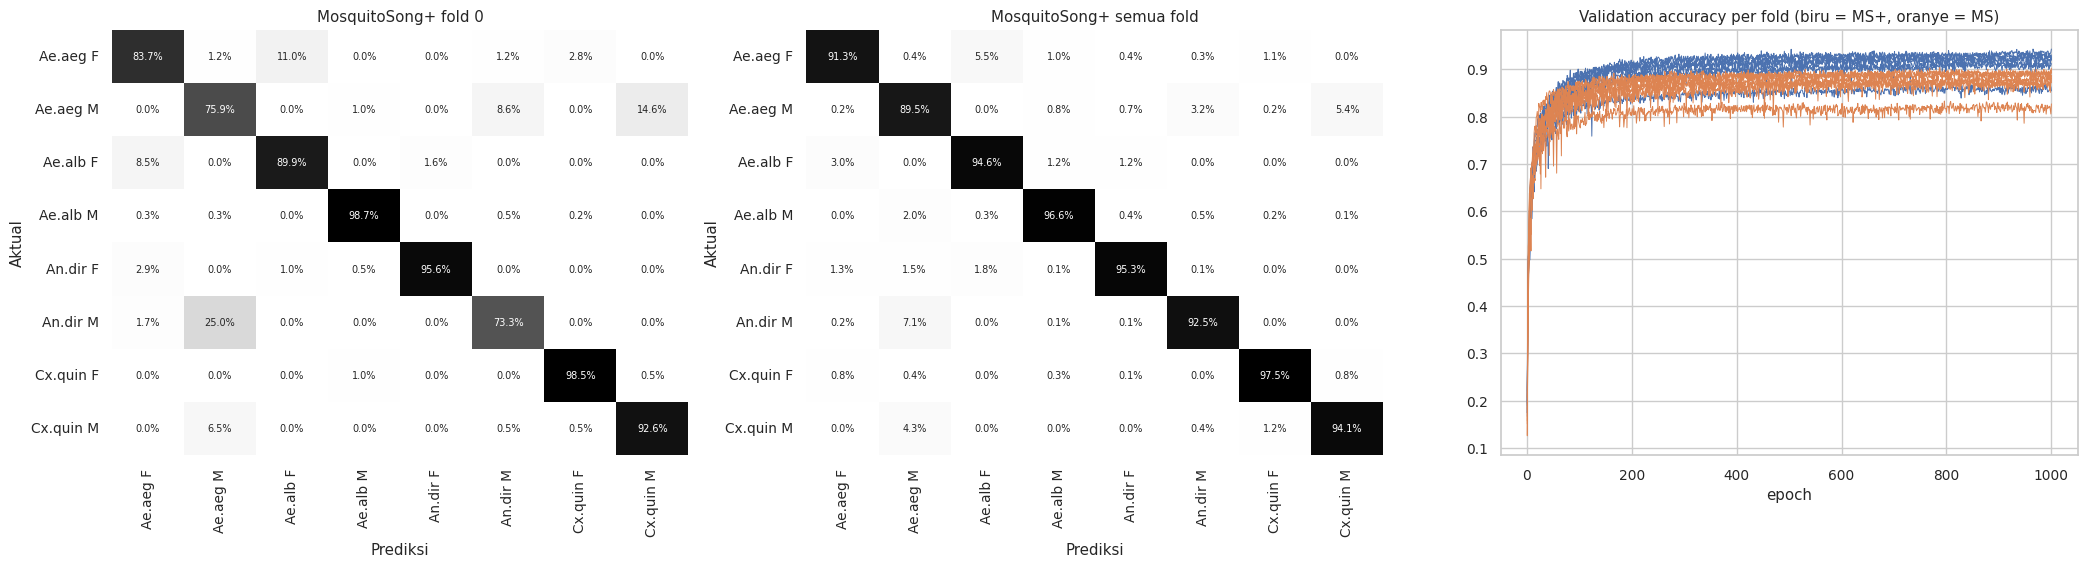

In [33]:
# Confusion matrix (paper Fig. 3 = satu fold) dan kurva validasi
if 'mosquitosong_plus' in RUNS:
    fig, ax = plt.subplots(1, 3, figsize=(21, 5.8))
    for a, (title, folds) in zip(ax, [('MosquitoSong+ fold 0', RUNS['mosquitosong_plus'][:1]),
                                       ('MosquitoSong+ semua fold', RUNS['mosquitosong_plus'])]):
        sns.heatmap(confmat(folds), annot=True, fmt='.1%', cmap='Greys', cbar=False, xticklabels=SHORT,
                    yticklabels=SHORT, ax=a, annot_kws={'size': 7})
        a.set(title=title, xlabel='Prediksi', ylabel='Aktual')
    for r, col in (('mosquitosong_plus', 'C0'), ('mosquitosong', 'C1')):
        for d in RUNS.get(r, []):
            h = hist(r, d['fold']); ax[2].plot(h.epoch, h.val_acc, lw=.7, color=col)
    ax[2].set(title='Validation accuracy per fold (biru = MS+, oranye = MS)', xlabel='epoch')
    plt.tight_layout(); plt.savefig('figures/01_confusion_kurva.png', dpi=150); plt.show()

In [34]:
def corrected_ttest(d, rho=0.1, alternative='two-sided'):
    """Corrected resampled t-test (Nadeau & Bengio, 2003) untuk selisih skor per fold d (k fold, test/train = rho/(1-rho)).
    Varians dikoreksi dengan faktor (1/k + rho/(1-rho)) karena set train antar fold saling tumpang tindih."""
    d = np.asarray(d, float); k = len(d)
    se = np.sqrt((1 / k + rho / (1 - rho)) * d.var(ddof=1))
    t = d.mean() / se if se > 0 else np.inf * np.sign(d.mean())
    p = {'two-sided': 2 * stats.t.sf(abs(t), k - 1), 'greater': stats.t.sf(t, k - 1), 'less': stats.t.cdf(t, k - 1)}[alternative]
    tq = stats.t.ppf(.975, k - 1)
    return t, p, (d.mean() - tq * se, d.mean() + tq * se)


# H1: MosquitoSong+ vs MosquitoSong pada fold yang sama (satu sisi, MS+ > MS)
if {'mosquitosong_plus', 'mosquitosong'} <= RUNS.keys():
    a, b = per_fold(RUNS['mosquitosong_plus']), per_fold(RUNS['mosquitosong'])
    common = a.index.intersection(b.index)
    rows = []
    for m in ('MF1', 'ACC'):
        d = (a.loc[common, m] - b.loc[common, m]).values
        t, p_c, ci = corrected_ttest(d, alternative='greater') if len(d) > 2 else (np.nan, np.nan, (np.nan, np.nan))
        rows.append({'metrik': m, 'n fold': len(common), 'MS+ rerata': a.loc[common, m].mean(), 'MS rerata': b.loc[common, m].mean(),
                     'selisih': d.mean(), '95% CI terkoreksi': f'[{ci[0]:+.3f}, {ci[1]:+.3f}]',
                     'MS+ menang': f'{(d > 0).sum()}/{len(d)}',
                     'Mann-Whitney p (MS+ > MS)': stats.mannwhitneyu(a.loc[common, m], b.loc[common, m], alternative='greater').pvalue,
                     'paired t p': stats.ttest_rel(a.loc[common, m], b.loc[common, m], alternative='greater').pvalue,
                     'corrected t p': p_c})
    tests = pd.DataFrame(rows)
    tests.to_csv('figures/01_uji_H1.csv', index=False)
    display(tests.round(4))
    display(pd.concat({'MosquitoSong+': a.loc[common, ['ACC', 'MF1']], 'MosquitoSong': b.loc[common, ['ACC', 'MF1']]}, axis=1).round(3))

,metrik,n fold,MS+ rerata,MS rerata,selisih,95% CI terkoreksi,MS+ menang,Mann-Whitney p (MS+ > MS),paired t p,corrected t p
0,MF1,7,0.9359,0.9047,0.0312,"[+0.018, +0.044]",7/7,0.0487,0.0001,0.0005
1,ACC,7,0.9409,0.9100,0.0310,"[+0.017, +0.045]",7/7,0.0364,0.0002,0.0008


MosquitoSong+        MosquitoSong       
               ACC    MF1          ACC    MF1
fold                                         
0            0.897  0.883        0.863  0.846
1            0.946  0.943        0.910  0.907
2            0.948  0.943        0.913  0.910
3            0.959  0.962        0.952  0.953
4            0.941  0.939        0.914  0.911
5            0.958  0.952        0.918  0.918
6            0.937  0.930        0.899  0.889

## 11. Catatan Deviasi

1. **Kode training tidak dirilis.** Hyperparameter yang tidak disebut paper ditentukan sendiri: batch 64, padding `valid`, time shift sirkular, seed 42 + fold.
2. **Protokol evaluasi rilis ≠ Eq. (1) paper.** Kode rilis memakai simulasi 2 mikrofon + `M2 - M1`; notebook ini mengikuti kode, dan training memakai domain sinyal yang sama.
3. **Set "noisy" hanya ±50 % ber-noise** karena `random.choice`; test akhir (noisy + clean) hanya ±25 % ber-noise (EDA 5.8).
4. **Noise train dan test tidak disjoint.** Test rilis mengambil segmen acak dari seluruh file noise; pembagian noise per fold tidak terdokumentasi. Enam dari dua belas file noise hampir hilang setelah `M2 - M1`.
5. **Data rilis +6,4 % epoch** dibanding Tabel 1, merata di semua kelas. Jumlah contoh test identik dengan Tabel 4.
6. **Checkpoint rilis (`cnn_model_min_val_round*.h5`) berarsitektur MosquitoSong** (221.576 parameter), bukan MosquitoSong+ Fig. 2 (348.808 parameter).
7. **Kebocoran antar rekaman** (EDA 5.10): 24,6 % epoch test berasal dari file yang juga terpotong ke train, dan sebagian file LowMic punya rekaman kembar kondenser.
8. **Framework:** TF/Keras versi image Kaggle (paper TF 2.4). Hasil GPU tidak bit-identik antar run.

## 12. Artefak dan Batasan

`runs/<model>/fold<k>/` berisi `best.weights.h5`, `history.csv`, `preds.npz` (probabilitas test noisy/clean × G dan validation), dan `config.json` (seed, versi paket, hyperparameter, waktu training, epoch awal bila dilanjutkan dari checkpoint). `config.json` ditulis terakhir dan menjadi penanda fold lengkap. Selama fold belum selesai, `ckpt/` menyimpan checkpoint tengah-fold dan dihapus otomatis setelah fold lengkap. Tabel dan gambar (termasuk EDA) ada di `figures/`; semuanya beserta `requirements.txt` dikemas ke `results.zip`.

Split mewarisi protokol rilis yang memotong rekaman menjadi window per fold. Window dari rekaman yang sama bisa berkorelasi, sehingga keterbatasan ini perlu disebut saat membahas hasil.

In [35]:
# Ekspor lingkungan (requirements) dan kemas semua artefak
import subprocess, zipfile
with open('requirements.txt', 'w') as f:
    f.write(subprocess.run([sys.executable, '-m', 'pip', 'freeze'], capture_output=True, text=True).stdout)
with zipfile.ZipFile('results.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    for pat in ('figures/*', 'logs/*', 'runs/*/fold*/*', 'mosq_lib.py', 'requirements.txt'):
        for f in glob.glob(pat):
            if os.path.isfile(f):
                z.write(f)
print(f"results.zip: {os.path.getsize('results.zip')/1e6:.1f} MB | requirements.txt: "
      f"{sum(1 for _ in open('requirements.txt'))} paket")

results.zip: 57.0 MB | requirements.txt: 936 paket
